# GlitchScope: finding where digital logic wastes energy on glitches, and fixing it automatically

**An open, SPICE-calibrated glitch-energy analyser with verified glitch-aware register placement for SKY130 logic**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sscs-ose/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/GlitchScope/GlitchScope.ipynb)
*IEEE SSCS Code-a-Chip, ISSCC 2027 submission* · Licence: Apache-2.0 ·
**Team Glitch Hunters:** Daney Alex (INL, EPFL) · Supervisor: Prof. Mahsa Shoaran (INL, EPFL) · [daney.alex@epfl.ch](mailto:daney.alex@epfl.ch) · GitHub [DaneyAlex5](https://github.com/DaneyAlex5)

*AI assistance.* The code, experiments and text were developed with substantial help from an AI assistant. The author defined the project, ran the server-side SPICE and GLOW experiments and reviewed the results.

Two circuits with the same function and the same RTL activity can burn very different amounts of energy. Unequal
path delays create glitches: short pulses that do no useful work but still charge and discharge capacitance. RTL
simulation never sees them, yet in a 16×16 array multiplier they account for 87 % of the logic's dynamic energy. This
notebook shows how we measure them, where they come from, and how most of them can be removed by moving registers.

**What is new**

1. Pulse filtering calibrated in SPICE, with open data. On top of per-cell rejection thresholds (as in Villegas &
   Vourkas, 2024) we model two further effects: a filtered pulse still costs energy, and the slope of the edge that
   ends a pulse shifts the threshold (open SKY130 data, 3,744 ngspice runs).
2. Attribution by measurement instead of tracing. We re-simulate the circuit with candidate gates made glitch-free and
   share joint savings with (sampled) Shapley values.
3. An automatic, certified fix. Register placement uses a MILP whose cost model is re-fitted to the energy measured on
   every placement tried, and every result is proved to be a legal retiming. When glitch-aware placement does not pay,
   the tool says so and returns minimum-register retiming. A separate study script also picks the supply voltage.
4. A closed loop in open tools. The fixed multiplier is placed and routed with OpenROAD, and the routed netlist, with
   its real clock tree and extracted wire capacitance, is simulated in ngspice (about 640 CPU-hours of SPICE in total).

**Key results** (16×16 array multiplier unless stated otherwise)

| | |
|---|---|
| Saving of the automatic fix, measured in transistor-level ngspice of the routed netlists (extracted cells, real flip-flops and clock tree, extracted wire capacitance), same latency and clock | **−36 %** (95 % CI 34–38 %), vs −24 % for min-period retiming; minimum-register retiming barely changes this design (−1.6 %, model); +14 % cell area; every routed layout DRC-clean in Magic (§6) |
| GlitchScope's own prediction of the same fix | −49 % before layout, −47.5 % after (it over-values glitch removal on deep arrays, §3) |
| Accuracy vs transistor-level SPICE on 7 circuits | glitch counts within 13 % on 5, ≤ 1.41× on deep logic (no filtering: 1.8–3×); logic energy of the 16×16 multiplier 1.48× (§3, §6) |
| Register placement on 16 standard benchmarks plus our multiplier (GlitchScope model; c6288 also in SPICE) | 26–42 % below minimum-register retiming on the three glitch-dominated circuits (c6288, EPFL `sin`, our multiplier), 16 % on c6288 in transistor-level SPICE; ≤ 1 % on the others, where the tool keeps minimum-register retiming (§7) |
| vs GLOW (MILP retiming, 1-h limit, also warm-started) | c6288: 21 % less energy in transistor-level SPICE (model 30–31 %); started from minimum-register retiming, GLOW keeps that placement on all four large designs; within 2.3 % on control logic (§7) |
| Where it does not pay | control logic (ITC'99), int8 operands, a Booth-multiplier PE and PicoRV32's multiplier: the tool returns minimum-register retiming (on PicoRV32 identical to the exact program: −5.4 %, 33 fewer flip-flops), so glitch-aware gains are confined to array-like logic where glitches are ≥ 60 % of the total energy (§7–9) |
| Placement and supply chosen together, at equal throughput (study script, GlitchScope model, −40 °C corners) | beats min-period retiming at every clock: 70 % vs 64–65 % saving at the tightest (§8) |

**Setup.** Run these two cells first; in Colab they also fetch the submission folder.

In [1]:
# ---- Environment setup: Colab or a fresh machine. Safe to re-run; skips whatever is already in place. ----
import os, sys, subprocess, pathlib
REPOS  = ["https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io",        # once the PR is merged
          "https://github.com/DaneyAlex5/sscs-ose-code-a-chip.github.io"]       # the PR's fork, until then
SUBDIR = "ISSCC27/submitted_notebooks/GlitchScope"
INSTALL_EDA_TOOLS = False   # True: Yosys, Icarus, ngspice, OpenROAD (OpenSTA) and SKY130 via micromamba (~5-10 min).
                            # Not needed to reproduce the figures (they use cached data); needed for live runs.
if not pathlib.Path("glitchscope").exists() and pathlib.Path("../glitchscope").exists():
    os.chdir("..")
if not pathlib.Path("glitchscope").exists():          # e.g. a bare Colab runtime: fetch the submission folder
    for i, repo in enumerate(r for r in REPOS if r.startswith(("https://", "file://"))):
        dest = pathlib.Path(f"cac{i}")
        if not dest.exists():
            subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse", repo, str(dest)])
            subprocess.run(["git", "-C", str(dest), "sparse-checkout", "set", SUBDIR])
        if (dest / SUBDIR / "glitchscope").exists():
            os.chdir(dest / SUBDIR)
            break
    else:
        raise RuntimeError(f"could not fetch {SUBDIR} from {REPOS}; clone the repository and open the notebook there")
for mod in ("numpy", "pandas", "matplotlib", "scipy"):
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", mod], check=True)
if INSTALL_EDA_TOOLS:                                  # the Code-a-Chip FAQ recipe (litex-hub / conda-forge packages)
    pref = pathlib.Path("conda-env").resolve()
    PINNED = ["python=3.10", "yosys=0.38_93_g84116c9a3", "iverilog=0_8_6897_g58dcf39db",   # last litex-hub
              "openroad=2.0_12381_g01bba3695", "ngspice=39.3_552_g902a62d2f",          # builds (2024)
              "open_pdks.sky130a=1.0.471_0_g97d0844"]
    if not (pref / "bin" / "yosys").exists():
        if not pathlib.Path("bin/micromamba").exists():
            pathlib.Path("bin").mkdir(exist_ok=True)
            subprocess.run(["curl", "-Lso", "bin/micromamba", "https://github.com/mamba-org/micromamba-releases/"
                            "releases/download/1.5.10-0/micromamba-linux-64"], check=True)
            os.chmod("bin/micromamba", 0o755)
        mm = ["bin/micromamba", "create", "--yes", "--prefix", str(pref), "--channel", "litex-hub", "--channel", "conda-forge"]
        if subprocess.run(mm + PINNED).returncode:          # pinned set did not solve: fall back to the FAQ recipe
            subprocess.run(mm + [x.split("=")[0] for x in PINNED[1:]], check=True)
    pdk = pref / "share" / "pdk" / "sky130A"
    os.environ["PATH"] = f"{pref}/bin:" + os.environ["PATH"]
    os.environ.update(GS_PDK_ROOT=str(pdk), GS_LIB=str(pdk / "libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib"),
                      GS_NGSPICE=str(pref / "bin/ngspice"), GS_YOSYS=str(pref / "bin/yosys"), GS_STA=str(pref / "bin/openroad"))
print("working directory:", pathlib.Path.cwd())

working directory: <repo>


In [2]:
import os, sys, json, csv, random, shutil, subprocess
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "glitchscope").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, matplotlib.pyplot as plt
from glitchscope import plots as P
from glitchscope.test_support import lib_path_or_none

LIB = lib_path_or_none()          # SKY130 HD tt_025C_1v80 Liberty (ORFS copy), from tools.env or $GS_LIB
if LIB is None:                   # bare runtime (e.g. Colab): fetch the open Liberty file (Apache-2.0, 12.8 MB) at the
    import urllib.request, hashlib                                       # OpenROAD-flow-scripts commit used for all results
    _lib = ROOT / "sky130_fd_sc_hd__tt_025C_1v80.lib"
    try:
        if not _lib.exists():
            urllib.request.urlretrieve("https://raw.githubusercontent.com/The-OpenROAD-Project/OpenROAD-flow-scripts/"
                                       "ef421749a1050a8e9a197e7dfcd05396807f889d/flow/platforms/sky130hd/lib/"
                                       "sky130_fd_sc_hd__tt_025C_1v80.lib", _lib)
        assert hashlib.md5(_lib.read_bytes()).hexdigest() == "12a1d61fcd2982fc8ba63993919c8ff8", "unexpected Liberty file"
        LIB = str(_lib); os.environ["GS_LIB"] = LIB
    except Exception as e:
        print("could not fetch the Liberty file (live cells will show cached results):", e)
env = dict(l.split("=", 1) for l in (ROOT / "tools.env").read_text().split() if "=" in l) if (ROOT / "tools.env").exists() else {}
env.update({k: v for k, v in os.environ.items() if k.startswith("GS_")})
print("Liberty available :", bool(LIB))
for key, tool in (("GS_NGSPICE", "ngspice"), ("GS_YOSYS", "yosys"), ("GS_STA", "sta")):
    p = env.get(key) or shutil.which(tool)
    print(f"{tool:8s} available:", bool(p and Path(p).exists()), "(only needed to recompute cached SPICE/synthesis data)")

Liberty available : True
ngspice  available: True (only needed to recompute cached SPICE/synthesis data)
yosys    available: True (only needed to recompute cached SPICE/synthesis data)
sta      available: True (only needed to recompute cached SPICE/synthesis data)


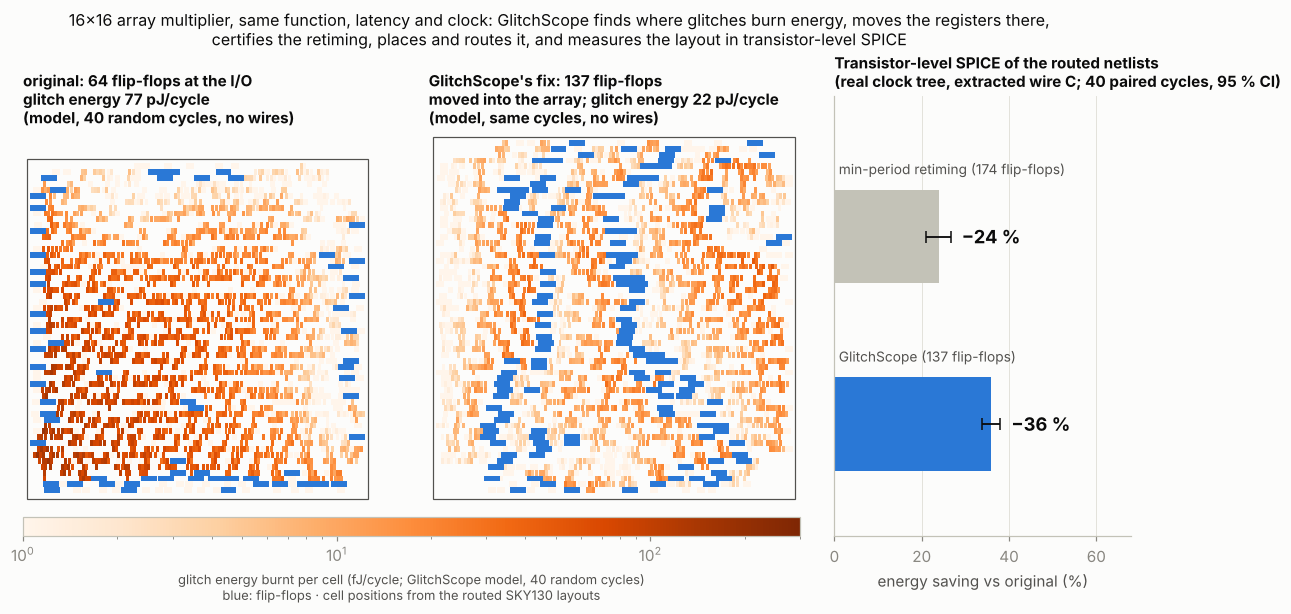

In [3]:
P.visual_abstract();

**How to read this notebook.** Sections 1 to 10 tell the story and take about 25 minutes; the appendix holds the
details, side studies and the full reproduction table. All figures are redrawn in a few seconds from cached results
in `data/`, and each cache names the script that recomputes it (A11). Cells marked **[live]** run the tool itself.
Section 1 and section 9 (a full analysis of a MAC unit in about 30 s, and `--optimize` on an 8×8 multiplier in about
7 min) only need the open SKY130 Liberty file, which the setup cell downloads automatically at a pinned commit, and
they print whether they reproduce the cached result. SPICE, synthesis and layout need the EDA tools (`INSTALL_EDA_TOOLS = True`
in the setup cell). We tested on Python 3.13; Colab should work as well, since only numpy, pandas, matplotlib and
SciPy are needed. Tool versions are listed in A11.

<details><summary><b>Glossary</b> (click)</summary>

| term | meaning |
|---|---|
| glitch | a transition that is not needed: the net settles back, or settles later than a zero-delay circuit would |
| M0 / M1 / M2 | glitch models: every pulse propagates / Liberty inertial delay / per-cell SPICE-calibrated filtering |
| retiming, lag | moving registers across gates without changing the function; a gate's lag is how many registers move across it (Leiserson–Saxe) |
| min-period retiming | retiming for the shortest clock period, then fewest registers (section 6's baseline) |
| FEAS retiming | Leiserson–Saxe's algorithm that moves registers only as far as needed to meet a given clock (section 7) |
| minimum-register retiming | retiming for the fewest registers at a given clock (an exact linear program here) |
| MILP | mixed-integer linear program; solved with the open solver HiGHS |
| Liberty, SPEF, SAIF | cell timing/power library; extracted wire parasitics; switching-activity file for power tools |
| PEX | parasitic extraction: transistor netlists of each cell with their extracted capacitances |
| SPICE (ngspice) | transistor-level circuit simulation, the reference for every model number here |
</details>

## 1. A glitch, step by step  [live]

A buffer chain delays one input of an XOR gate. When `S` rises, the XOR sees its two inputs change at different times
and briefly outputs 1, although its final value is 0. This is a generated glitch. How much energy it costs depends on
whether the pulse survives the next gate, and simulators disagree about that. We compare three pulse models
throughout the notebook:

* M0, transport delay: every pulse propagates.
* M1, classical inertial delay: a pulse narrower than the gate's delay is removed.
* M2, GlitchScope: a pulse is removed below a threshold measured in SPICE for that particular cell, and it is still
  charged the energy it draws while being filtered (section 2).

1 buffer(s), M0: Y events [(190.1, 1), (232.2, 0)] -> pulse 42.1 ps; filtered: 0
1 buffer(s), M1: Y events [] -> no pulse; filtered: 1
1 buffer(s), M2: Y events [(190.1, 1), (232.2, 0)] -> pulse 42.1 ps; filtered: 0
2 buffer(s), M0: Y events [(190.1, 1), (304.6, 0)] -> pulse 114.5 ps; filtered: 0
2 buffer(s), M1: Y events [(190.1, 1), (304.6, 0)] -> pulse 114.5 ps; filtered: 0
2 buffer(s), M2: Y events [(190.1, 1), (304.6, 0)] -> pulse 114.5 ps; filtered: 0


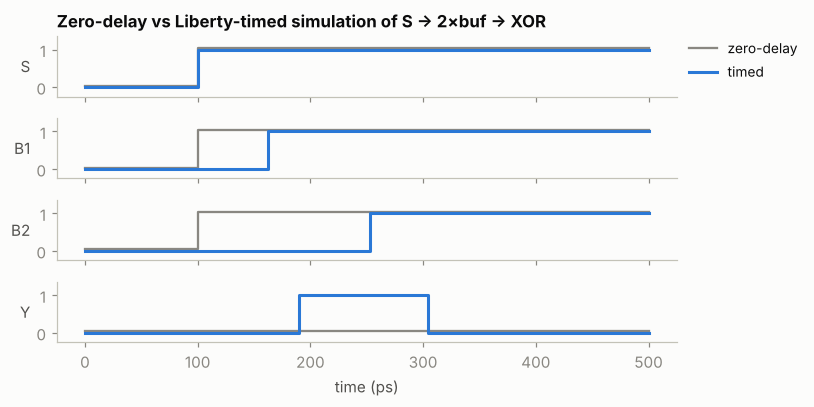

In [4]:
from glitchscope.model import Cell, Network, StimulusEpoch, ps_to_fs
from glitchscope.sim import PulseSimulator
from glitchscope.liberty import parse_liberty_file, LibertyDelayProvider

def chain_xor(n):
    cells, prev = [], "S"
    for i in range(1, n + 1):
        cells.append(Cell(f"U_B{i}", "BUF", {"A": prev}, f"B{i}", 0, 0, "sky130_fd_sc_hd__buf_1", "X")); prev = f"B{i}"
    cells.append(Cell("U_X", "XOR2", {"A": "S", "B": prev}, "Y", 0, 0, "sky130_fd_sc_hd__xor2_1", "X"))
    return Network(["S"], ["Y"], cells, {"S": 0})

CACHE = ROOT / "data/notebook/hazard_demo.json"
nets = ["S", "B1", "B2", "Y"]
if LIB:
    lib = parse_liberty_file(LIB); dp = LibertyDelayProvider(lib)
    from glitchscope.m2model import M2Model
    ep = [StimulusEpoch(ps_to_fs(100), {"S": 1}, 1)]
    lines = []
    for nbuf in (1, 2):
        net = chain_xor(nbuf)
        for model in ("M0", "M1", "M2"):
            r = PulseSimulator(net, dp, model, r_filter=M2Model(), input_slew_fs_by_net={"S": ps_to_fs(10)},
                               primary_output_load_ff_by_net={"Y": 1.157}).run(ep)
            ys = [(round(e.time_fs / 1000, 1), e.new_value) for e in r["trace"] if e.net == "Y"]
            w = f"pulse {ys[1][0] - ys[0][0]:.1f} ps" if len(ys) == 2 else "no pulse"
            lines.append(f"{nbuf} buffer(s), {model}: Y events {ys or '[]'} -> {w}; filtered: {len(r['suppressed'])}")
    timed = PulseSimulator(chain_xor(2), dp, "M0", input_slew_fs_by_net={"S": ps_to_fs(10)},
                           primary_output_load_ff_by_net={"Y": 1.157}).run(ep)
    events = [(e.time_fs / 1000, e.net, e.new_value) for e in timed["trace"]]
    CACHE.write_text(json.dumps({"lines": lines, "events": events}))
else:
    cached = json.loads(CACHE.read_text()); lines, events = cached["lines"], [tuple(e) for e in cached["events"]]
    print("(no Liberty file configured: showing the cached result of this cell)")
print("\n".join(lines))
init = {n: 0 for n in nets}
ideal = {"init": init, "events": [(100, "S", 1), (100, "B1", 1), (100, "B2", 1)]}
tm = {"init": init, "events": events}
P.hazard_waveforms(ideal, tm, nets, 500, "Zero-delay vs Liberty-timed simulation of S → 2×buf → XOR")

With two buffers the pulse at `Y` is 114.5 ps wide and every model keeps it. With one buffer it shrinks to 42 ps.
M0 keeps it, M1 removes it, and M2 keeps it again, because in SPICE a positive pulse through an XOR2 survives down to
about 0.7× the gate delay. So the three models already disagree on the simplest possible hazard.

Internally, GlitchScope treats each input vector or clock cycle as one epoch. It runs a zero-delay reference next to
the timed simulation and splits the transitions of every net into the functionally required one and excess (glitch)
pairs. Each event remembers its causal parents, which lets us label every glitch as *generated*, *propagated* or
*merged*.

## 2. When does a pulse die? SPICE calibration of M2

For 12 SKY130 HD cells (inv, buf, nand2, nor2, and2, or2, xor2, xnor2, a21oi, o21ai, nand3, a22oi) we injected single
pulses of width $w$ = 3–600 ps at several input slews and loads and in both polarities, and measured the output
excursion and the supply energy in ngspice with the SKY130 transistor models (3,456 runs). Everything is normalised by
the cell's own SPICE delay, $r = w / t_{pd}$, so the model does not depend on how well Liberty and SPICE agree in
absolute terms (A2).

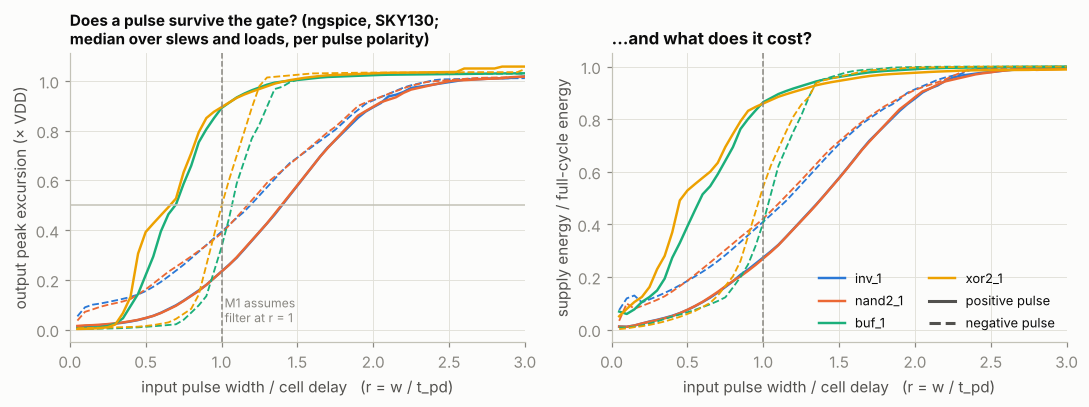

In [5]:
P.pulse_curves();

M2 model: r_filter = a + b * (input slew / delay), per cell and output polarity; cells: 12
energy of a pulse filtered right at the threshold: median 53 % of a full cycle (range 46-67 %, 128 conditions)


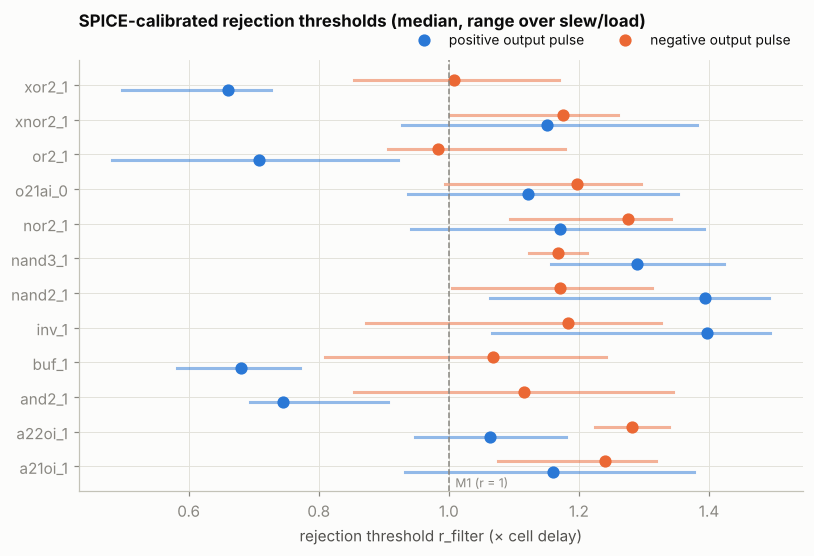

In [6]:
P.r_filter_dots();
m = json.loads((ROOT / "data/m2/m2_model.json").read_text())
print("M2 model: r_filter = a + b * (input slew / delay), per cell and output polarity; cells:", len(m["cells"]))
se = np.array([float(r["S_E_at_filter"]) for r in csv.DictReader(open(ROOT / "data/m2/m2_conditions.csv"))])
print(f"energy of a pulse filtered right at the threshold: median {100 * np.median(se):.0f} % of a full cycle "
      f"(range {100 * se.min():.0f}-{100 * se.max():.0f} %, {len(se)} conditions)")

Three things came out of this sweep. First, the classical inertial assumption ($r = 1$) is wrong in both directions.
Inverting gates need $r \approx$ 1.1–1.4 before a pulse reaches VDD/2 at their output, while positive pulses through
non-inverting gates (buf, and2, or2, xor2) survive down to $r \approx 0.7$. (The number of calibration conditions
differs per cell; nand3 and a22oi have fewer.)

Second, a filtered pulse is not free. A pulse that never reaches VDD/2 still draws a median 53 % of a full
transition's energy at the threshold, so M2 charges every pulse, surviving or filtered, $S_E(r)\cdot E_{cycle}$ from
the measured curve.

Third, the edge that ends a pulse matters. Deep inside the logic, the two edges of a glitch come from different paths
and their slopes can differ by hundreds of picoseconds. A second sweep (288 runs) shows that a slow closing edge kills
wider pulses: the threshold moves by a fraction α of the slope difference. The per-cell medians are 0.28–0.39 when the
closing input edge rises and 0–0.21 when it falls, with single conditions up to 0.48 (figure in A1). M2 therefore
compares $w - \alpha\,(s_{close} - s_{open})$ with its threshold.

Sometimes this decision can only be made after the pulse's leading edge has already propagated. In that case the
simulator rolls the epoch back and re-simulates it, so the result stays deterministic.

## 3. Is it right? Transistor-level validation of whole circuits

We simulated the same stimuli in ngspice with every cell at transistor level: our 8-bit ripple-carry and Kogge-Stone
adders and 4×4 multiplier, ISCAS'85 c432 and c880 (mapped with Yosys/ABC), an 8×8 NOR-array multiplier (544 cells),
and a multiply-accumulate unit with real `dfxtp` flip-flops. The SPICE cells are parasitic-extracted from the PDK's
own layouts with Magic. This matters: the PDK only ships schematic cell netlists without diffusion or wiring
capacitance, and the extracted cells draw 16–25 % more energy per transition (A2). Glitch transitions are counted at
the 50 % crossings of every internal net, minus the functionally required ones.

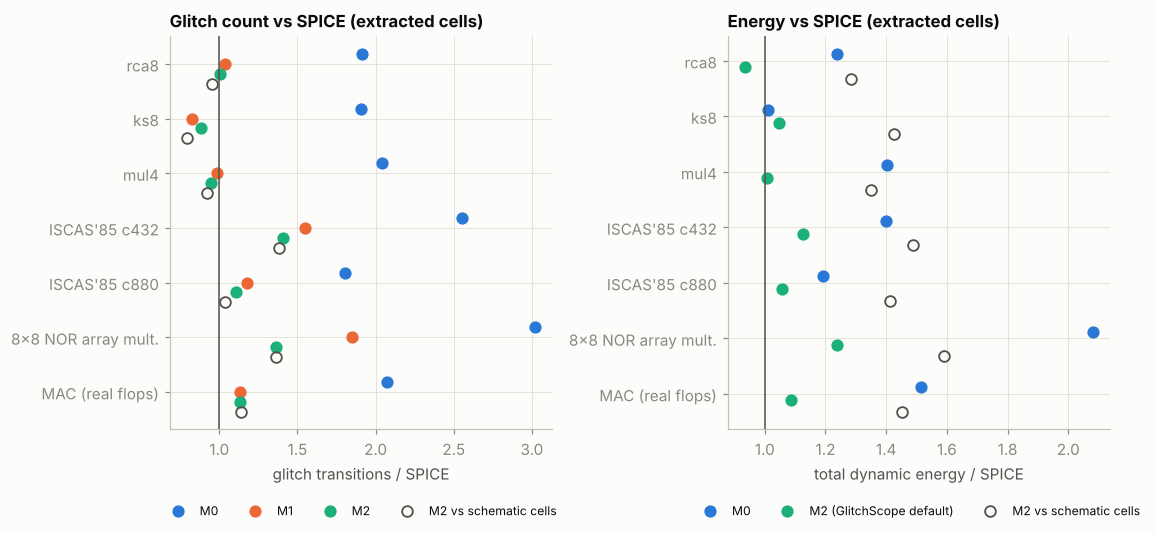

In [7]:
P.spice_validation();

Without filtering (M0), glitch transitions are over-counted 1.8–3.0× and energy by up to 2.1×. With M2, glitch counts
are within 13 % on five of the seven circuits (0.89–1.13×), and the exact number of transitions of each net in each
vector matches SPICE 97.5–99.4 % of the time on five of the six circuits for which we have per-net data. Energy is
within 13 % on six of seven (0.93–1.13×, using GlitchScope's default SPICE-scaled cell energy).

Deep reconvergent logic remains the hard case: c432 is at 1.41× and the NOR array at 1.36× in glitch count (1.79×
before the closing-edge correction), and 1.24× in energy. GlitchScope's absolute glitch energies for array
multipliers are therefore somewhat high, and section 6 checks what this means for the fix. The diagnosis and a
per-cycle check on the MAC are in A2 and A9.

## 4. Where to fix: measured attribution

The usual way to locate glitch "sources" is structural: find gates whose inputs are glitch-free but whose outputs
glitch, trace their pulses forward and add up the power along the way (trace-and-sum). GlitchScope measures an
intervention instead: the glitch energy saved when a set $S$ of gates is made glitch-free, meaning that each of these
gates moves once, straight to its final value:

$$\mathrm{saving}(S) \;=\; E_{glitch}(\text{design}) \;-\; E_{glitch}\big(\text{design with the gates in } S \text{ glitch-free}\big)$$

Only the vectors in which a gate was active are re-simulated, with an exact bound on its fan-out cone. Savings
overlap, so the joint saving of a set is shared out with Shapley values (estimated from sampled gate orderings: 12 by
default, 4 for the large report in A5), and a greedy search builds a good joint set.

rca8: Spearman(structural, interventional) = 0.89; top-6 joint 64% vs sum of singles 89%


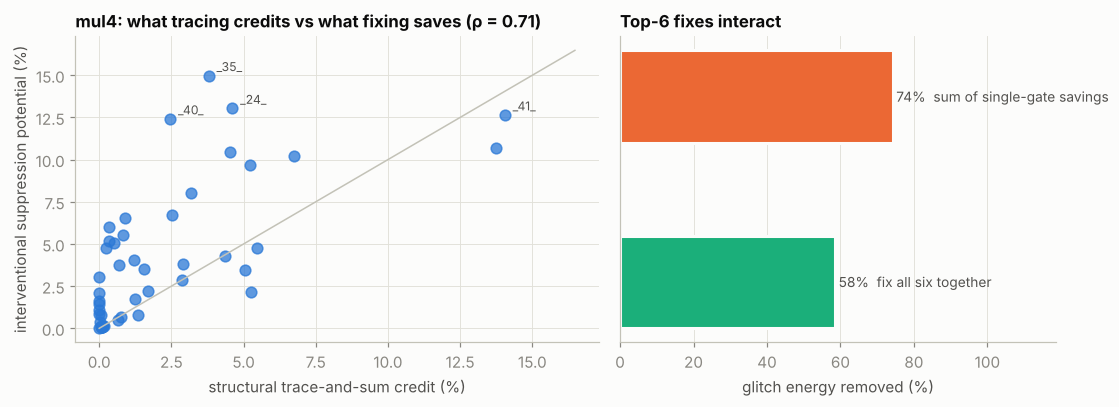

In [8]:
P.attribution("mul4");
c = json.loads((ROOT / "data/bench/counterfactual_rca8.json").read_text())
print(f"rca8: Spearman(structural, interventional) = {c['spearman']:.2f}; "
      f"top-6 joint {100*c['joint_top']:.0f}% vs sum of singles {100*c['sum_single_top']:.0f}%")

Two observations from the small circuits. Credit is not the same as saving: in the 4×4 multiplier, three of the four
best single fixes (`_35_` 15 %, `_24_` 13 %, `_40_` 12 %) get only 2–5 % structural credit, and the rank correlation
between the two views is 0.71. And savings do not add up: the top six gates together remove 58 % (mul4) and 64 %
(rca8), not the 74 % and 89 % that their single savings sum to.

**At scale, blocks matter more than gates.** We built a 2,368-cell 16×16 array multiplier with the ISCAS c6288
architecture (`bench/gen_arraymul.py`, verified against `a*b`). Glitches are 87 % of its logic's dynamic energy, yet
none of the 12 most promising single gates removes more than 2 %. So GlitchScope attributes groups instead: each
adder row, and each band of logic depth.

rows  : best joint set r09 (49 %) -> r12 (65 %) -> r07 (75 %) -> r11 (77 %)   [41 interventions, 10 min on 2 cores]
levels: best joint set depth 041-050 (60 %) -> depth 021-030 (77 %) -> depth 061-070 (88 %)   [22 interventions, 6 min on 2 cores]
single cells (12 screened): r05c11_g4 1.9 %, r06c10_g3 1.3 %, r05c07_g7 1.1 %; top-6 together 4.5 %
highest traced credit -> measured: r02c14_g5 2.7 % -> 0.27 %, r02c14_g8 2.5 % -> 0.29 %, r02c13_g5 2.3 % -> -0.38 %, r02c08_g5 2.2 % -> 0.05 %


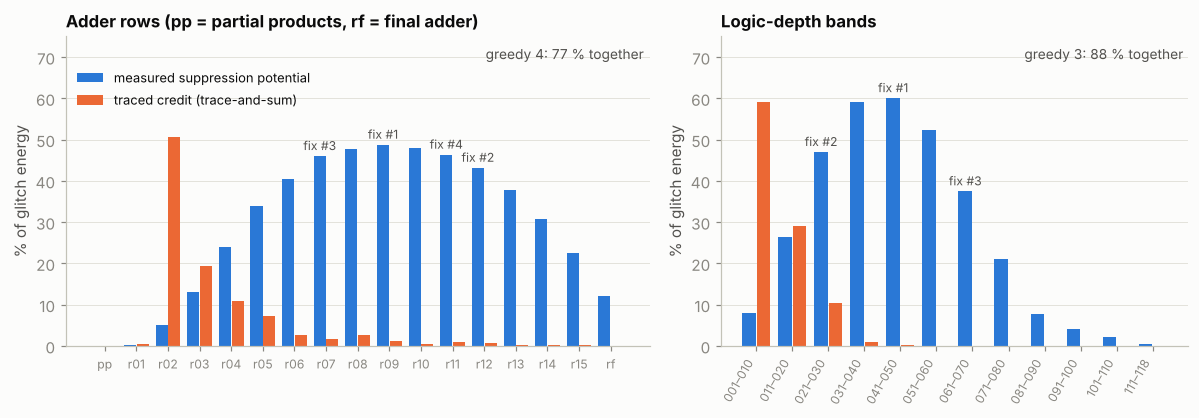

In [9]:
st = json.loads((ROOT / "data/bench/arraymul16_study.json").read_text())
P.group_attribution(ROOT / "data/bench/arraymul16_study.json");
done = 0
for key in ("rows", "levels"):
    r = st[key]
    print(f"{key:6s}: best joint set " + " -> ".join(f"{g} ({100*v:.0f} %)" for g, v in r["greedy"]) +
          f"   [{r['evaluations'] - done} interventions, {r['seconds']/60:.0f} min on 2 cores]")
    done = r["evaluations"]
c = st["cells"]
print(f"single cells ({c['screened']} screened): " + ", ".join(f"{k} {100*c['single'][k]:.1f} %" for k in c["top"][:3]) +
      f"; top-6 together {100*c['joint_top']:.1f} %")
print("highest traced credit -> measured: " + ", ".join(f"{k} {100*c['structural'][k]:.1f} % -> {100*v:.2f} %"
                                                       for k, v in list(c["structural_top_gain"].items())[:4]))

The two views point to opposite ends of the array. Trace-and-sum credits the early rows, where glitches are first
generated (row 2 alone gets 51 %). But making row 2 glitch-free saves only 5 %, because the skewed arrival times are
re-created at every following row. The measured potential peaks in the middle instead (rows 7–11, 46–49 % each). The
best joint sets, rows 9, 12 and 7 together (75 %) or a glitch barrier roughly every 20 logic levels (88 %), point to
where a register stage would pay off. Local edits such as resizing or pin swaps buy less than 1 % here (A5; for the
4×4 multiplier, A4).

## 5. A register where the analysis points, placed and routed

An attribution is only useful if it changes a design. We gave the multiplier input and output registers (V0), then
one extra pipeline stage placed by each of the two views, and took all three through the open RTL-to-layout flow
(Yosys and OpenROAD-flow-scripts: placement, clock tree, routing, RC extraction):

| | pipeline register | chosen by |
|---|---|---|
| V0 | none | baseline |
| V1 | after adder row 3 | trace-and-sum credit (rows 2–3 get most of it; the register goes below them) |
| V2 | after adder row 9 | GlitchScope's measured potential |

After layout, GlitchScope reads the routed netlist together with the extracted wire capacitance (SPEF), and OpenSTA
computes total power, including flip-flops and clock tree, from GlitchScope's glitch-accurate activity (SAIF).

     glitch pJ/cyc  glitch pJ/cyc  total power      area   slack  latency
      (pre-layout)  (post-layout)   (post, mW)     (µm²)    (ns) (cycles)
V0            71.1           80.8         7.22     12240    2.25        2
V1            56.2           62.9         6.29     13764    3.53        3
V2            38.9           44.7         5.08     13721    6.90        3
SPEF 6_final.spef: 2608 nets, 3616 fF wire capacitance on logic nets


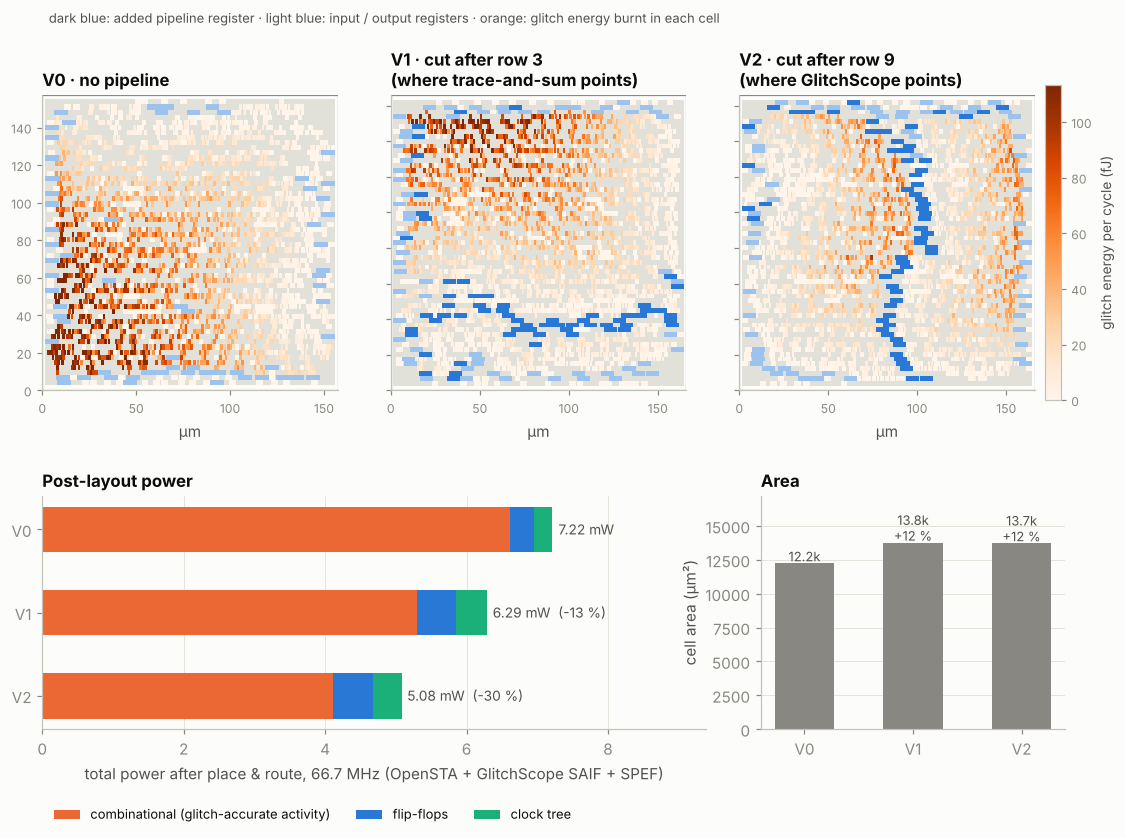

In [10]:
P.layout_study();
L = json.loads((ROOT / "data/layout/summary.json").read_text())
V, pre = L["variants"], L["prelayout"]
print(f"{'':3s} {'glitch pJ/cyc':>14s} {'glitch pJ/cyc':>14s} {'total power':>12s} {'area':>9s} {'slack':>7s} {'latency':>8s}")
print(f"{'':3s} {'(pre-layout)':>14s} {'(post-layout)':>14s} {'(post, mW)':>12s} {'(µm²)':>9s} {'(ns)':>7s} {'(cycles)':>8s}")
for v in ("v0", "v1", "v2"):
    r = V[v]
    print(f"{v.upper():3s} {pre[v]['E_glitch_pJ']:14.1f} {r['glitchscope']['E_glitch_pJ']:14.1f} "
          f"{r['opensta_mW']['Total']:12.2f} {r['area_um2']:9.0f} {r['opensta_mW']['slack_ns']:7.2f} {r['latency_cycles']:8d}")
print(V["v2"]["parasitics"])

Where the register goes decides the saving. V2 cuts post-layout power by **30 %** and V1 by 13 %, at the same +12 %
area (any cut across the array registers about the same number of signals, 62 here) and one extra cycle of latency.
The pre-layout analysis already predicts the post-layout ranking: wire capacitance raises each variant's
combinational energy by 13–16 % (glitch energy by 12–15 %, see the table), but the order and size of the savings
hold.

To be fair, a designer optimising for speed might also put the cut near the middle. What GlitchScope adds is the
measurement, and the observation that the classical credit-based ranking points somewhere else.

## 6. Fixing it automatically, with certified results checked in SPICE

`glitchscope --optimize` places the registers itself and writes out the corrected netlist. It works in four steps.

1. Candidates. It generates legal Leiserson–Saxe retimings (same latency) or added pipeline stages (`--latency N`),
   both from arrival-time cuts and from a measurement-calibrated MILP that minimises
   $\sum_v \beta_v t_v + E_{reg}\sum_u R_u$. Here $t_v$ is a cell's arrival time after the last register (the later
   a cell settles, the more unequal path delays its inputs have accumulated, and a register resets that to zero) and
   $R_u$ is the number of registers on net $u$. The weights $\beta_v$ are re-fitted per cell to the glitch energy
   measured on every placement tried so far. The MILP is solved by the open solver HiGHS with a fixed
   branch-and-bound budget.
2. Measurement. Every candidate netlist is re-simulated with SPICE-calibrated filtering and charged for its flip-flop
   and clock-tree energy.
3. Certification. Each reported netlist passes a structural proof that it is a legal Leiserson–Saxe retiming of the
   original: the logic is identical, and every register count is explained by one lag per gate
   (`scripts/retiming_certificate.py`; all 14 netlists reported in sections 6–9 pass, and deliberately broken netlists fail; equivalence holds from
   corresponding initial states). SAT-based sequential equivalence with Yosys and ABC additionally proves the 8×8
   placements and the 16×16 cuts placement; on the 16×16 MILP placement it times out, as SAT usually does on
   multipliers. Outputs are also compared on every simulated cycle and in an Icarus Verilog co-simulation.
4. A conservative choice. Among all measured placements, including the reference retimings, the tool picks the one
   with the fewest flip-flops within 5 % of the lowest energy (`--area-tie`). This is a heuristic, but smaller model
   differences are not reliable on deep logic: two 8×8 placements about 3 % apart in the model tie in SPICE below.

The test case is the registered 16×16 multiplier (V0: latency 2, 66.7 MHz), with no extra latency allowed:

register placement                  total   glitch  flops  critical path   (pJ per cycle, pre-layout)
original                             92.6     73.8     64       11.15 ns
min-register retiming                91.1     72.5     64       10.94 ns
min-period retiming                  62.3     31.8    174        4.44 ns
GlitchScope, arrival-time cuts       57.1     24.2    198        5.37 ns
GlitchScope, calibrated MILP         47.8     21.3    137        6.43 ns
108 placements measured and verified; search took 99 min on 2 cores
mul16_p: original 92.46 pJ -> best 52.38 pJ (177 flops, latency +1)
mac: original 3.11 pJ -> best 3.11 pJ (18 flops, latency +0)


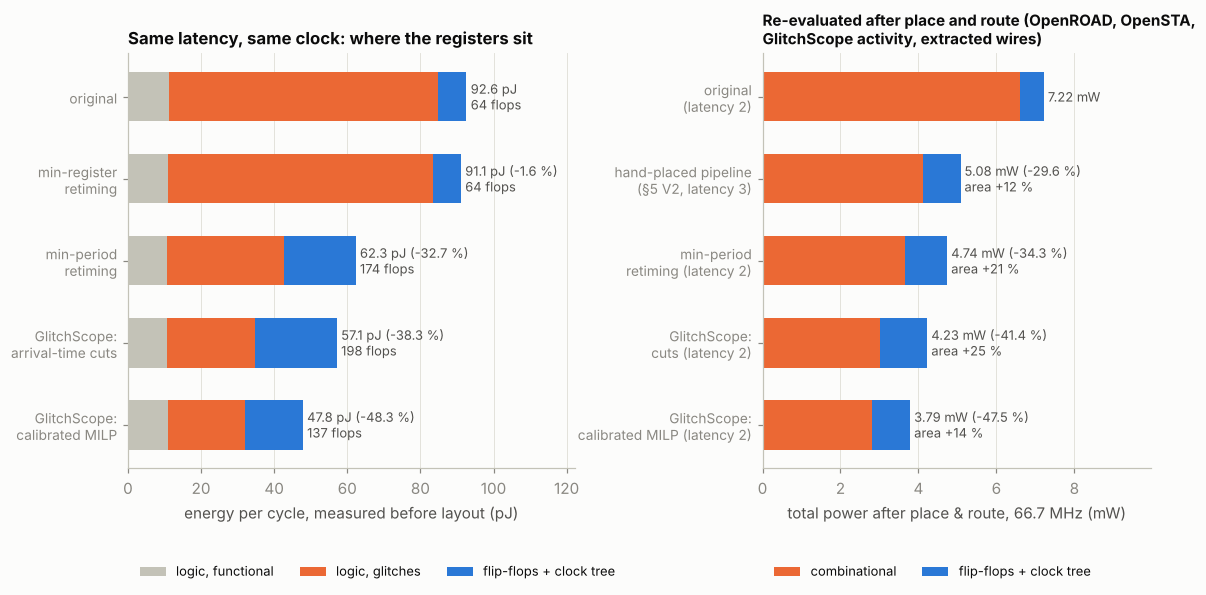

In [11]:
P.glitchfix();
O = json.loads((ROOT / "data/glitchfix/mul16_r/optimize.json").read_text())
print(f"{'register placement':32s}{'total':>9s}{'glitch':>9s}{'flops':>7s}{'critical path':>15s}   (pJ per cycle, pre-layout)")
for k, lab in (("original", "original"), ("min_register", "min-register retiming"),
               ("timing_driven", "min-period retiming"), ("best_cuts", "GlitchScope, arrival-time cuts"),
               ("best_milp", "GlitchScope, calibrated MILP")):
    r = O[k]
    print(f"{lab:32s}{r['total'] / 1e3:9.1f}{r['glitch'] / 1e3:9.1f}{r['flops']:7d}{r['period_ps'] / 1e3:12.2f} ns")
print(f"{len(O['candidates'])} placements measured and verified; search took {O['seconds'] / 60:.0f} min on 2 cores")
for k in ("mul16_p", "mac"):
    Q = json.loads((ROOT / f"data/glitchfix/{k}/optimize.json").read_text())
    o, g = Q["original"], Q["glitch_aware"]
    print(f"{k}: original {o['total'] / 1e3:.2f} pJ -> best {g['total'] / 1e3:.2f} pJ ({g['flops']} flops, "
          f"latency +{Q['latency']})")

Keeping latency and clock and only moving registers, GlitchScope retimes the 64 input and output registers into the
array (137 flip-flops). By its own activity estimate this cuts post-layout power from 7.22 to 3.79 mW (−47.5 %, +14 %
cell area). Min-period retiming reaches 4.74 mW (−34 %, 174 flip-flops, +21 % area) and minimum-register retiming
−1.6 %.

These numbers inherit GlitchScope's over-count on deep arrays, so we simulated the designs at transistor level, with
every cell parasitic-extracted, real flip-flops and exactly the stimulus GlitchScope used, both before layout (bars
below) and as routed (diamonds). Long runs are split into chunks that replay the preceding cycles; this matches one
long run to within 0.01 % per cycle.

*Baselines of this multiplier differ slightly between sections (about 88–96 pJ/cycle) because each study uses its own
stimulus; within a study all designs see identical stimulus.*

8x8 multiplier               flops   SPICE vs orig.         95 % CI GlitchScope vs orig.  (pJ/cycle)
original                        32   10.61    +0.0%                       12.57    +0.0%
min-period retiming             71   11.72   +10.4%   [+6.1, +15.6]       12.30    -2.2%
GlitchScope, arrival cuts *     43    9.89    -6.8%    [-8.4, -5.1]       10.98   -12.7%
GlitchScope, MILP               46    9.79    -7.7%   [-10.1, -5.0]       10.68   -15.1%
  * GlitchScope's choice. Its logic energy saved: SPICE 28 %, GlitchScope 31 %; GlitchScope/SPICE logic 1.29 (original), flip-flops 0.97–0.99; 48 paired cycles, 29 CPU-hours of ngspice

16x16 multiplier             flops   SPICE vs orig.         95 % CI GlitchScope vs orig.  (pJ/cycle)
original                        64   66.39    +0.0%                       93.90    +0.0%
min-period retiming            174   53.18   -19.9%  [-22.8, -16.8]       62.23   -33.7%
GlitchScope, arrival cuts      198   50.56   -23.9%  [-26.4, -21.0]       57.0

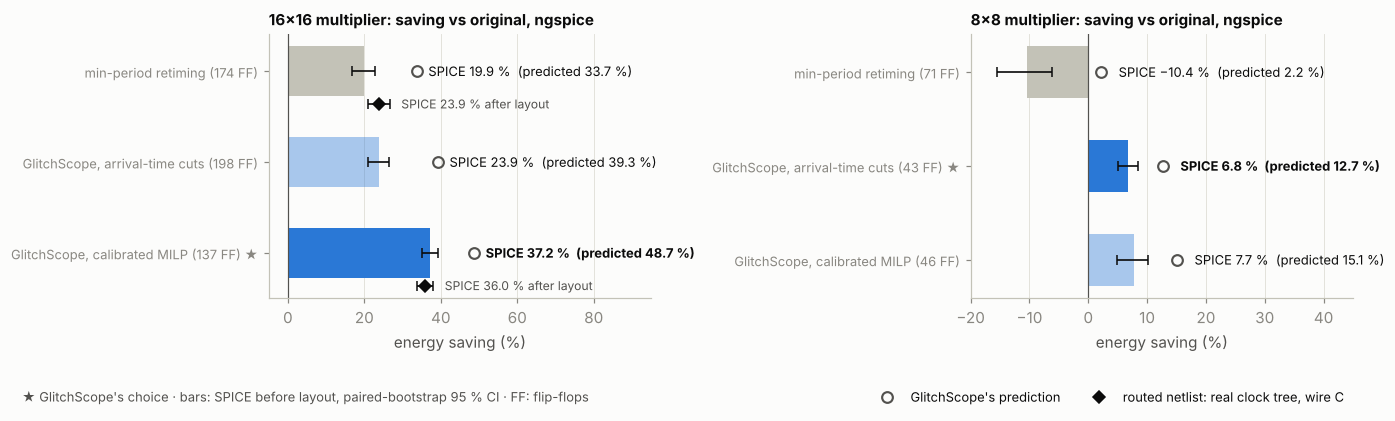

In [12]:
P.spice_confirmation();
LAB = {"original": "original", "timing_driven": "min-period retiming", "best_cuts": "GlitchScope, arrival cuts",
       "best_milp": "GlitchScope, MILP"}
for case, title in (("mul8_r", "8x8 multiplier"), ("mul16_r", "16x16 multiplier")):
    SC = json.loads((ROOT / f"data/glitchfix/{case}/spice_confirm_pex.json").read_text())
    pick = json.loads((ROOT / f"data/glitchfix/{case}/optimize.json").read_text())["glitch_aware"]["flops"]
    D, o = SC["designs"], SC["designs"]["original"]
    print(f"{title:28s}{'flops':>6s}{'SPICE':>8s}{'vs orig.':>9s}{'95 % CI':>16s}{'GlitchScope':>12s}{'vs orig.':>9s}  (pJ/cycle)")
    for k in ("original", "timing_driven", "best_cuts", "best_milp"):
        if k not in D:
            continue
        r = D[k]
        ci = f"[{-100 * r['saving_spice_ci95'][1]:+.1f}, {-100 * r['saving_spice_ci95'][0]:+.1f}]" if "saving_spice_ci95" in r else ""
        sv = lambda a, b: f"{100 * (a / b - 1):+8.1f}%"                                 # noqa: E731
        lab = LAB[k] + (" *" if k.startswith("best") and r["flops"] == pick else "")
        print(f"{lab:28s}{r['flops']:6d}{r['spice']['total'] / 1e3:8.2f}{sv(r['spice']['total'], o['spice']['total'])}"
              f"{ci:>16s}{r['glitchscope']['total'] / 1e3:12.2f}{sv(r['glitchscope']['total'], o['glitchscope']['total'])}")
    g = next(r for k, r in D.items() if k.startswith("best") and r["flops"] == pick)
    print(f"  * GlitchScope's choice. Its logic energy saved: SPICE {100 * g['logic_saving_spice']:.0f} %, GlitchScope "
          f"{100 * g['logic_saving_glitchscope']:.0f} %; GlitchScope/SPICE logic {o['glitchscope']['logic'] / o['spice']['logic']:.2f} "
          f"(original), flip-flops {min(r['glitchscope']['flops'] / r['spice']['flops'] for r in D.values()):.2f}–"
          f"{max(r['glitchscope']['flops'] / r['spice']['flops'] for r in D.values()):.2f}; {g['paired_cycles']} paired cycles, "
          f"{sum(d['cpu_hours'] for d in D.values()):.0f} CPU-hours of ngspice\n")

Before layout, GlitchScope's choice saves 37.2 % (95 % CI 35.0–39.2 %, 40 paired cycles), min-period retiming 19.9 %
and the 198-flip-flop cuts placement 23.9 %, which is the order GlitchScope ranks them in. On the 8×8 version
GlitchScope saves 6.8 % (5.1–8.4 %) while min-period retiming costs 10.4 %. There its two candidates tie (−6.8 % and
−7.7 %), and the rule takes the one with fewer flip-flops.

GlitchScope does over-predict the size of the saving (−49 % and −13 %). It over-counts glitches on deep arrays (logic
energy 1.48× and 1.29× of SPICE; flip-flops 0.93–0.99×), so it over-values removing them, but the ranking holds. The
intervals come from a paired bootstrap over cycles (5,000 resamples); they cover stimulus sampling, not model or
extraction uncertainty.

**Measured on the routed layouts.** Finally we simulated the three routed netlists exactly as OpenROAD wrote them:
resized cells, hold buffers, the real clock tree on its own supply, every net's extracted wire capacitance (SPEF,
lumped) and 24 parasitic-extracted cell types, on the same 40 cycles with inputs at the constrained 0.5 ns delay
(`scripts/spice_confirm_postlayout.py`, 193 CPU-hours). No analytic flip-flop or clock-tree estimate is left in this
number. All ten routed layouts in this notebook are DRC-clean: Magic's full SKY130 rule deck finds 0 violations on
each GDS, and the router reports 0 DRC and 0 antenna violations in every route log included (A10). There is no LVS, and wires carry no RC delay
here.

In [13]:
PLR = json.loads((ROOT / "data/glitchfix/mul16_r/spice_postlayout.json").read_text())
print(f"{'routed layout':24s}{'logic':>8s}{'flip-flops':>12s}{'clock tree':>12s}{'total':>8s}   {'saving (95 % CI)'}   (pJ/cycle, ngspice)")
lab = {"original": "original", "timing_driven": "min-period retiming", "glitchscope": "GlitchScope"}
for k, r in PLR["designs"].items():
    ci = f"{-100 * r['saving']:+.1f} % [{-100 * r['saving_ci95'][1]:.1f}, {-100 * r['saving_ci95'][0]:.1f}]" if "saving" in r else ""
    print(f"{lab[k]:24s}{r['logic'] / 1e3:8.1f}{r['flops'] / 1e3:12.1f}{r['clock_tree'] / 1e3:12.1f}{r['total'] / 1e3:8.1f}   {ci}")
g = PLR["glitchscope_vs_timing_driven"]
print(f"GlitchScope's layout vs min-period retiming's: {100 * g['saving']:.1f} % less energy "
      f"[{100 * g['ci95'][0]:.1f}, {100 * g['ci95'][1]:.1f}]")

routed layout              logic  flip-flops  clock tree   total   saving (95 % CI)   (pJ/cycle, ngspice)
original                    66.0         5.0         2.8    73.7   
min-period retiming         41.3         9.5         5.3    56.1   -23.9 % [-26.7, -20.9]
GlitchScope                 33.7         8.5         5.0    47.2   -36.0 % [-38.0, -33.8]
GlitchScope's layout vs min-period retiming's: 15.8 % less energy [14.1, 17.7]


The saving survives layout: **−36.0 % (33.8–38.0 %)** against −23.9 % (20.9–26.7 %) for min-period retiming, i.e.
15.8 % (14.1–17.7 %) less energy than the min-period layout. The real clock tree is 4–11 % of each total and the wires
add 13–30 % to the logic energy, but the ranking does not change. This SPICE number, rather than the −47.5 % from
OpenSTA with GlitchScope's activity, is the one we quote.

**The tool also knows when not to act.** It leaves the multiply-accumulate unit of section 9 unchanged. On a 4-lane
int8 dot-product processing element the glitch-aware placements tie with minimum-register retiming, so the tool
returns that cheaper design (−10 % and −20 % post-layout power for two multiplier architectures, 5–8 % less area; A6).
Adding a pipeline stage (`--latency 1`) saves less than pure retiming.

## 7. Standard benchmarks and comparison with the state of the art

`bench/fetch_benchmarks.py` fetches ISCAS'85/'89, ITC'99 and the EPFL suite at pinned commits and maps them with
Yosys/ABC onto the calibrated cells (sources and netlists stay local). Each of the 68 circuits (6–17,860 cells; we
summarise the 65 with at least 20 cells) gets 30 random cycles at about 1.25× its critical path:

In [14]:
S = json.loads((ROOT / "data/benchmarks/suite.json").read_text())
names = {"iscas85": "ISCAS'85", "iscas89": "ISCAS'89", "itc99": "ITC'99", "epfl": "EPFL"}
print(f"{'suite':9s}{'circuits':>9s}{'cells':>15s}{'glitch share M2':>26s}{'M0 / M2':>9s}")
for su, lab in names.items():
    rows = [r for r in S.values() if r["suite"] == su and r["cells"] >= 20]
    m2 = np.array([100 * r["M2"]["glitch_share"] for r in rows]); m0 = np.array([100 * r["M0"]["glitch_share"] for r in rows])
    print(f"{lab:9s}{len(rows):9d}{min(r['cells'] for r in rows):8d}–{max(r['cells'] for r in rows):<6d}"
          f"   median {np.median(m2):4.1f} % ({m2.min():4.1f}–{m2.max():4.1f})"
          f"{np.median(m0[m2 > 1] / m2[m2 > 1]):8.2f}x")

suite     circuits          cells           glitch share M2  M0 / M2
ISCAS'85        10     113–1201     median 29.0 % (14.1–74.8)    1.53x
ISCAS'89        22      58–6629     median 12.6 % ( 7.0–32.2)    1.60x
ITC'99          18      25–17860    median 21.6 % ( 7.6–50.7)    1.45x
EPFL            15      86–15824    median 17.8 % ( 1.6–84.3)    1.67x


At the suite medians, glitches are 13–29 % of the combinational dynamic energy, ranging from 1.6 % for EPFL `dec` to
84 % for the EPFL 64×64 multiplier (c6288: 75 %). Ignoring filtering (M0) inflates the share by a median factor of
1.5.

**Register placement.** Each design has to meet a target clock: eight ITC'99 control circuits at 1.1× their minimum
period, and eight arithmetic circuits plus our multiplier, wrapped with input and output registers, both at their
own clock and at 1.1×. We compare against two references, measured the same way as GlitchScope's result: exact
minimum-register retiming (a linear program), and FEAS retiming, Leiserson and Saxe's feasibility algorithm, which
moves registers only as far as needed to meet the target clock. At a design's own clock FEAS returns the original
itself, unlike section 6's min-period retiming. These runs use 16 sampled cycles and a coarser search, which is why
they find a 121-flip-flop placement for our multiplier instead of 137.

ITC'99 at 1.1x T_min: saving vs exact min-register retiming 0.0–1.0 %, vs FEAS 0–44 %; glitches are 1–21 % of their total energy
c6288_r@0.0      glitch/total  61 %   saving vs min-register  26.2 %  (64 -> 125 flops)
c6288_r@1.1      glitch/total  61 %   saving vs min-register  14.3 %  (94 -> 124 flops)
mul16_v0@0.0     glitch/total  80 %   saving vs min-register  42.2 %  (64 -> 121 flops)
mul16_v0@1.1     glitch/total  80 %   saving vs min-register  27.1 %  (88 -> 135 flops)
sin_r@0.0        glitch/total  76 %   saving vs min-register  39.0 %  (48 -> 133 flops)
sin_r@1.1        glitch/total  76 %   saving vs min-register   9.1 %  (109 -> 140 flops)


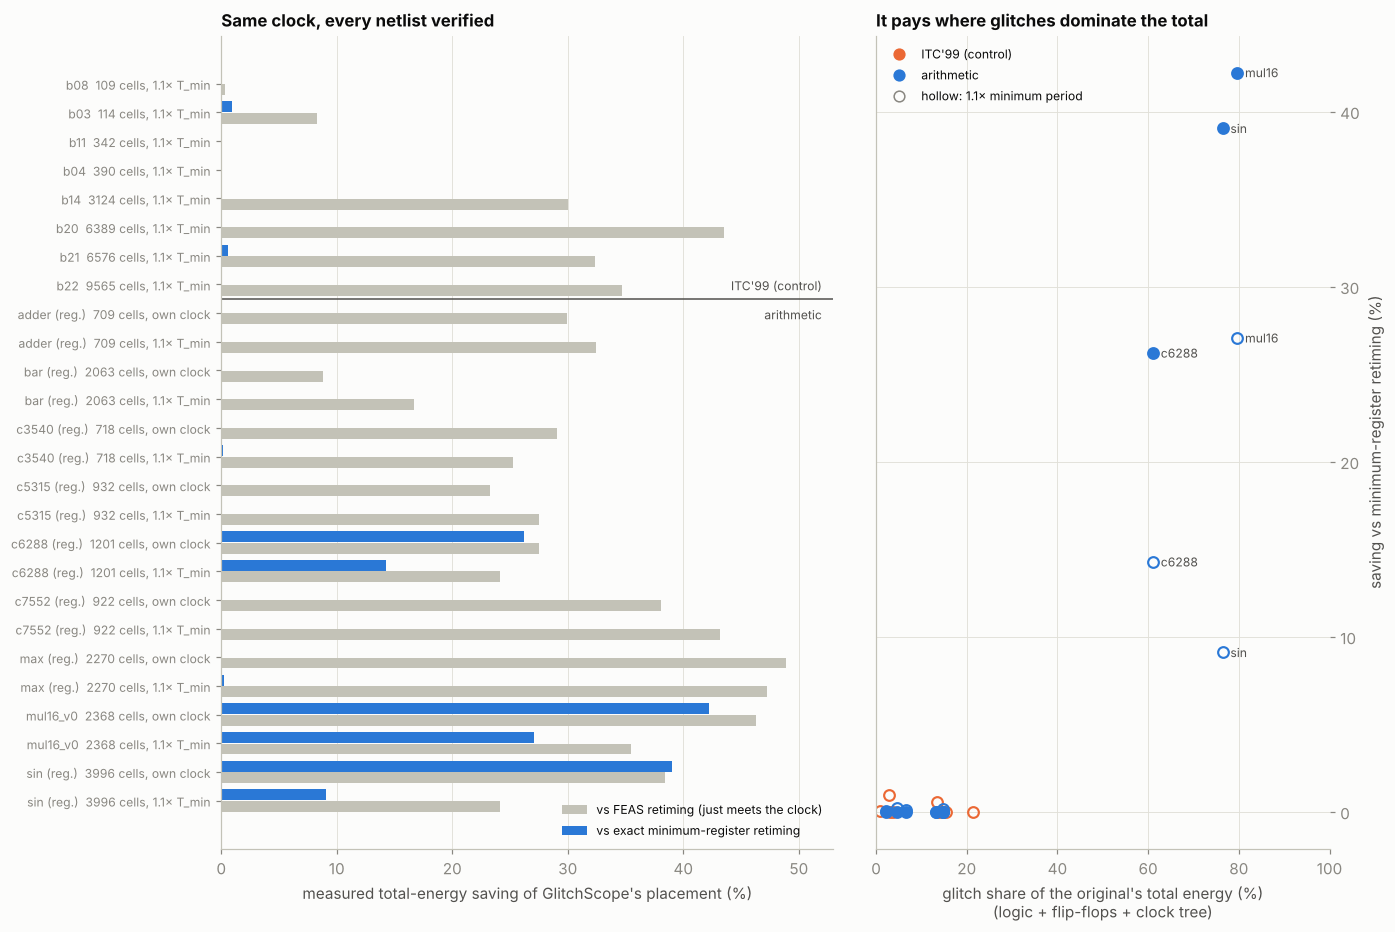

In [15]:
P.retiming_benchmarks();
R = json.loads((ROOT / "data/benchmarks/retiming.json").read_text())
import re
ctl = [r for k, r in R.items() if re.match(r"b\d\d@", k)]
print("ITC'99 at 1.1x T_min: saving vs exact min-register retiming "
      f"{min(100 * r.get('saving_vs_classic', 0) for r in ctl):.1f}–{max(100 * r.get('saving_vs_classic', 0) for r in ctl):.1f} %, "
      f"vs FEAS {min(100 * r.get('saving_vs_timing_driven', 0) for r in ctl):.0f}–"
      f"{max(100 * r.get('saving_vs_timing_driven', 0) for r in ctl):.0f} %; "
      f"glitches are {min(100 * r['original']['glitch'] / r['original']['total'] for r in ctl):.0f}–"
      f"{max(100 * r['original']['glitch'] / r['original']['total'] for r in ctl):.0f} % of their total energy")
for k in sorted(R):
    r = R[k]
    if r.get("saving_vs_classic", 0) > 0.02:
        print(f"{k:16s} glitch/total {100 * r['original']['glitch'] / r['original']['total']:3.0f} %   saving vs min-register "
              f"{100 * r['saving_vs_classic']:5.1f} %  ({r['classic']['flops']} -> {r['glitchscope']['flops']} flops)")

On control logic (ITC'99) there is nothing to gain: GlitchScope is 0–1.0 % better than minimum-register retiming,
because once every flip-flop and the clock tree are counted, glitches are only 1–21 % of the energy. On
glitch-dominated arithmetic, GlitchScope ends up 26–42 % below minimum-register retiming at the designs' own clock
(c6288 26 %, `sin` 39 %, our multiplier 42 %), and 9–27 % below it at the tighter clock. We see a pattern, though not
yet a rule: every circuit whose glitches are ≥ 60 % of its *total* energy gained, none at ≤ 22 % did, and the two
designs in between (int8 data, 27 %; PicoRV32's multiplier, 36 %; the two dot-product PEs of A6, 39 % and 46 %) did
not either.

**Head-to-head with GLOW.** GLOW (Liu et al., IWLS 2026; ICCAD 2026, to appear) is a recent open MILP retimer for
glitch power. We let GLOW choose the lags on the same retiming graphs, with GlitchScope's costs and period constraint,
using either its own switching estimate or our simulated toggle rates (Gurobi 13, 32 threads, 1 h per run). GLOW ran on
8 of the 17 placement benchmarks: the five ITC'99 circuits up to b14 and the three glitch-dominated arithmetic designs;
we left out the larger ITC'99 circuits (6–10 k cells), since GLOW found no placement within 1 h already at 2.4–4 k cells.
GlitchScope then writes, verifies and measures GLOW's result exactly like its own (`scripts/glow_compare.py`):

In [16]:
import glob
print(f"{'circuit':16s}{'min-register':>14s}{'GLOW, own est.':>16s}{'GLOW, sim.':>14s}{'GLOW warm':>14s}{'GlitchScope':>14s}"
      "   (pJ per cycle, flip-flops)")
for f in sorted(glob.glob(str(ROOT / "data/glow/*/result.json"))):
    g = json.loads(Path(f).read_text())
    cell = lambda r: f"{r['total'] / 1e3:8.2f} ({r['flops']:3d})" if r and "total" in r else f"{'-':>14s}"
    print(f"{g['name'] + ('' if g['factor'] <= 0 else ' @1.1'):16s}{cell(g['min_register']):>14s}{cell(g.get('glow_est')):>16s}"
          f"{cell(g.get('glow_sim')):>14s}{cell(g.get('glow_wsim')):>14s}{cell(g.get('glitchscope_from_retiming_json')):>14s}")
print("every placement verified cycle by cycle and meeting the target period; '-' in the GLOW columns: no feasible")
print("placement within 1 h; GLOW warm (rerun on the four large designs only): started from minimum-register retiming")
C = json.loads((ROOT / "data/glitchfix/c6288_r/spice_confirm_pex.json").read_text())
print(f"\nc6288 in transistor-level ngspice ({C['glitchscope_vs_min_register']['cycles']} paired cycles, 95 % CI):")
for k, lab in (("glitchscope_vs_min_register", "minimum-register retiming"), ("glitchscope_vs_glow_sim", "GLOW (sim. rates)")):
    r = C[k]
    print(f"  GlitchScope vs {lab:26s} {100 * r['saving']:5.1f} % less energy  [{100 * r['ci95'][0]:.1f}, {100 * r['ci95'][1]:.1f}]")

circuit           min-register  GLOW, own est.    GLOW, sim.     GLOW warm   GlitchScope   (pJ per cycle, flip-flops)
b03 @1.1            5.52 ( 46)      5.46 ( 46)    5.47 ( 46)             -    5.46 ( 46)
b04 @1.1            8.77 ( 66)      8.97 ( 68)    8.77 ( 66)             -    8.77 ( 66)
b08 @1.1            3.17 ( 29)      3.18 ( 29)    3.17 ( 29)             -    3.17 ( 29)
b11 @1.1            4.13 ( 34)      4.13 ( 34)    4.13 ( 34)             -    4.13 ( 34)
b14 @1.1           52.30 (378)               -             -   52.30 (378)   52.30 (378)
c6288_r            42.57 ( 64)     45.68 (124)   44.69 ( 92)   42.57 ( 64)   31.41 (125)
mul16_v0           88.08 ( 64)               -             -   88.08 ( 64)   50.89 (121)
sin_r             100.74 ( 48)               -             -  100.74 ( 48)   61.42 (133)
every placement verified cycle by cycle and meeting the target period; '-' in the GLOW columns: no feasible
placement within 1 h; GLOW warm (rerun on the four large desig

On control logic the two tools are within 0.3 % of each other with our toggle rates and within 2.3 % with GLOW's own
estimate; neither finds glitch-aware headroom. On c6288, GlitchScope's placement uses 30–31 % less energy than GLOW's
in the model, with a third of the glitch energy (8.1 vs 23.0–25.6 pJ). GLOW stopped at its 1-hour limit 20–33 % away
from its own optimum, and on the 2,368–3,996-cell designs (our multiplier, b14, `sin`) it found no feasible placement
within 1 h. To give it a fair second chance we reran it on these four designs (c6288 with both switching models, five
runs of 1 h) starting from the exact minimum-register retiming (`scripts/glow_warmstart.py`; Gurobi accepted every
start). In all five runs GLOW kept that starting placement
for the full hour, so on these designs its result is minimum-register retiming, which GlitchScope beats by 26–42 % on
c6288, `sin` and our multiplier and matches on b14. GlitchScope searched for 0.5 h on c6288 and 0.7–2.9 h on the
larger designs (2 cores).

We also checked c6288 at transistor level, with the four placements on 40 paired cycles
(`scripts/spice_confirm_parallel.py`, 136 CPU-hours). GlitchScope's placement uses 16.0 % (13.0–18.6 %) less energy
than minimum-register retiming and 21.4 % (18.9–23.5 %) less than GLOW's, against 26 % and 30 % in the model; GLOW's
placement is 5.4 % *worse* than the original (+3 % in the model): GLOW minimises its own probabilistic power estimate,
which does not see the energy measured here. As on the multiplier, the model overstates the size of the saving but
not the ranking. In GLOW's favour, it was tuned for commercial synthesis and power analysis on Nangate45, not for
SKY130 graphs and our cost model.

## 8. Robustness: corners, supply voltage and mismatch (simulation)

We took the original, min-period retiming and GlitchScope's placement, all chosen once at the typical corner, and
evaluated them at the 12 Liberty corners of the PDK (−40 to 100 °C, 1.28–1.95 V, with the clock at 1.25× the
original's critical path at each corner) and under local mismatch (a random delay factor per gate instance,
σ = 1.8–2.8 % from the PDK's SPICE Monte-Carlo models; 30 dies shared by all designs, at 1× and 3× σ):

12 corners: glitch/logic energy 86.3–86.7 %; saving min-period 33.2–36.8 %, GlitchScope 47.1–49.8 %
mismatch x1 (30 dies): original 94.7 ± 0.39 pJ; saving min-period 35.1 % (worst die 34.5 %), GlitchScope 48.3 % (worst 47.8 %); GlitchScope better on 30/30 dies
mismatch x3 (30 dies): original 95.2 ± 0.72 pJ; saving min-period 35.0 % (worst die 34.0 %), GlitchScope 48.5 % (worst 47.7 %); GlitchScope better on 30/30 dies


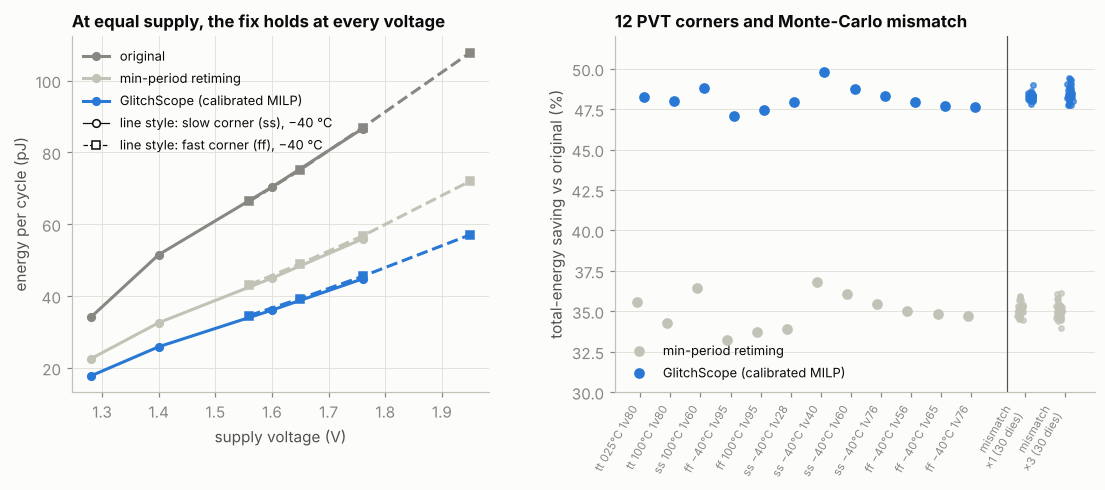

In [17]:
P.robustness();
PV = json.loads((ROOT / "data/pvt/pvt.json").read_text())
MC = json.loads((ROOT / "data/mismatch/study.json").read_text())
sv = lambda k: [100 * r[k]["saving"] for r in PV.values()]                       # noqa: E731
print(f"12 corners: glitch/logic energy {min(100 * r['glitch_share_original'] for r in PV.values()):.1f}–"
      f"{max(100 * r['glitch_share_original'] for r in PV.values()):.1f} %; saving min-period {min(sv('timing_driven')):.1f}–"
      f"{max(sv('timing_driven')):.1f} %, GlitchScope {min(sv('glitchscope')):.1f}–{max(sv('glitchscope')):.1f} %")
for s, r in sorted(MC["runs"].items()):
    print(f"mismatch x{float(s):g} ({r['dies']} dies): original {r['total_mean']['original'] / 1e3:.1f} ± "
          f"{r['total_sd']['original'] / 1e3:.2f} pJ; saving min-period {100 * r['saving_mean']['timing_driven']:.1f} % "
          f"(worst die {100 * r['saving_min']['timing_driven']:.1f} %), GlitchScope {100 * r['saving_mean']['glitchscope']:.1f} % "
          f"(worst {100 * r['saving_min']['glitchscope']:.1f} %); GlitchScope better on {r['glitchscope_beats_timing']}/{r['dies']} dies")

One placement serves all corners: it saves 47.1–49.8 % at every corner (min-period: 33.2–36.8 %), and recalibrating
M2 in SPICE at the most extreme corner gives 47.9 % vs 33.9 %. It is also robust to mismatch, with at least 47.7 % on
every die and a better result than min-period retiming on 30 of 30 dies at each level. That is what one would
expect, since the glitches come from path-length differences of tens of gate delays, not from picoseconds of skew.
Keep in mind that these are model savings (SPICE gave 36–37 % where the model says 49 %, section 6).

**Choosing placement and supply together.** Min-period retiming leaves more slack (4.4 vs 6.4 ns critical path), and
slack can buy a lower supply: against the fixed-supply choice it wins at the tightest clocks by 1–3 points.
GlitchScope's voltage-aware mode (`scripts/vdd_aware_study.py`) therefore reruns the search at tighter timing targets
(5.5 and 4.8 ns), measures every placement, the references included, at the characterised supplies of the PDK's
−40 °C corners (interpolating in supply between them), and for each throughput keeps the lowest energy at the lowest
supply that meets the clock. Liberty
leakage is below 0.1 fJ per cycle at these corners, against tens of pJ of dynamic energy, so we can ignore it here
(`scripts/leakage_check.py`).

*Reading the figure:* each panel is one −40 °C corner family; a point is one throughput (clock frequency), and its
period is given at that corner's speed. The logic is several times slower there than at the typical corner, where the
5.5 / 4.8 ns targets and the critical paths in the text are measured. Savings are against the original at its own
lowest supply meeting the same clock, so they include supply scaling for every design. At the fast corner the
voltage-aware choice coincides with the fixed-supply one, so only one GlitchScope line is drawn there.

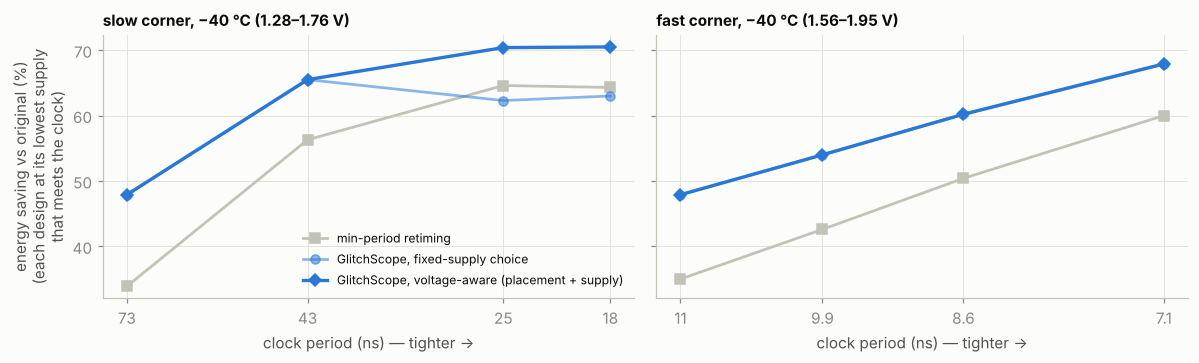

In [18]:
P.vdd_aware();

With both chosen, GlitchScope wins at every throughput: 70 % against 64–65 % at the two tightest clocks, using a
156-flip-flop placement whose 4.2 ns critical path (typical corner) is no longer than min-period retiming's. Both
designs then run within 6 mV of the same supply (1.31–1.39 V), so the 5–6-point gap is glitch energy and not supply.
At the other clocks both run at the lowest characterised supply (48–68 % against 34–60 %). Retiming combined with
supply scaling is not new (e.g. Chabini & Wolf, TVLSI 2004); what is new here is doing it with measured glitch
energy, and finding that slack and glitch removal need not compete. These are model numbers, on certified retimings.

**Does it depend on random operands?** We ran the same three designs on two other operand streams
(`scripts/workload_study.py`): slowly varying 16-bit signal samples multiplied by coefficients, and 8-bit operands
resembling a quantised neural-network layer (ReLU activations, half of them zero, times small weights):

In [19]:
W = json.loads((ROOT / "data/glitchfix/mul16_r/workloads.json").read_text())
lab = {"uniform": "uniform random", "dsp_16bit": "16-bit signal samples", "dnn_int8": "int8 DNN-like operands"}
print(f"{'operands':24s}{'original':>10s}{'glitch/total':>14s}{'min-period':>15s}{'GlitchScope':>13s}   (pJ/cycle; saving)")
for k in ("uniform", "dsp_16bit", "dnn_int8"):
    r = W[k]
    print(f"{lab[k]:24s}{r['original']['total'] / 1e3:10.1f}{100 * r['glitch_share_original']:13.0f} %"
          f"{-100 * r['timing_driven']['saving']:+14.0f} %{-100 * r['glitchscope']['saving']:+12.0f} %")

operands                  original  glitch/total     min-period  GlitchScope   (pJ/cycle; saving)
uniform random                90.0           79 %           -32 %         -47 %
16-bit signal samples         70.4           78 %           -31 %         -45 %
int8 DNN-like operands        10.5           27 %           +94 %         +55 %


On signal-processing data the fix holds (−45 % against −31 % for min-period retiming). On int8 data neither placement
pays: glitches drop to 27 % of the total, and the placement chosen on random data now costs 55 % *more* (min-period:
+94 %) because its extra flip-flops dominate. Given that data, though, `--optimize` notices
(`scripts/workload_optimize.py`) and returns minimum-register retiming with 64 flip-flops (−2.7 %). The lesson is
that placement has to be chosen with representative stimulus.

## 9. Use it on your own design  [live]

Any gate-level netlist mapped to a Liberty library works (edge-triggered flip-flops, async clear/preset), driven by a
testbench VCD or by random vectors:

```bash
bench/synth_seq.sh bench/rtl/mac.v mac                       # Yosys -> SKY130 HD netlist
iverilog -o tb bench/rtl/mac.v bench/rtl/tb_mac.v && vvp tb  # any RTL testbench -> mac.vcd
glitchscope --netlist bench/netlists/mac.v --vcd mac.vcd --lib sky130_fd_sc_hd__tt_025C_1v80.lib --out report/
glitchscope ... --optimize                                   # + verified glitch-aware register placement
```

Useful options are `--groups hier | level:8 | regex:<pattern>` (group attribution), `--fixes N` (what-if edits),
`--spef` (post-layout wire capacitance), `--sample N` (long testbenches, with a confidence interval) and
`--workers N`. Any Liberty library works; we analysed the same multiplier in six open technologies from 180 nm down
to a predictive 2 nm (A8). A run writes a self-contained interactive `report.html`, CSV tables, a glitch-only VCD for
GTKWave and a SAIF for OpenSTA. The demo below is a registered 4×4 multiply-accumulate unit (130 cells + 18
flip-flops, 303 cycles at 200 MHz):

GlitchScope report  (M2, 130 cells, 18 flops, 303 cycles @ 5000 ps)
  output check vs testbench: 3020/3020 match
  functional energy :    584.0 fJ/cycle
  glitch energy     :    422.3 fJ/cycle  (42.0 % of dynamic)
  glitches          : generated 1269, propagated 3382, merged 674, filtered 1634
  top glitch CONSUMERS (where energy is burnt): _206_ 4.6%, _197_ 3.9%, _211_ 3.6%, _214_ 3.5%, _225_ 3.4%
  WHERE TO FIX (interventional suppression potential, % of glitch energy removed if the gate were glitch-free):
      _181_ 10.7%, _183_ 10.4%, _197_ 9.7%, _213_ 8.4%, _186_ 8.3%, _206_ 7.8%
    fixing these 6 together removes 40.0% (naive sum of singles would claim 55.3%)
    Shapley share of that joint saving: _181_ 7.7%, _183_ 4.5%, _197_ 5.0%, _213_ 8.9%, _186_ 9.5%, _206_ 4.4%
    best joint fix set (greedy): _181_ (10.7%) -> _186_ (19.9%) -> _213_ (29.1%) -> _197_ (35.3%) -> _175_ (38.8%) -> _211_ (42.0%)
  glitch energy by input/state toggles (fJ per toggle): acc[3] 89.8, acc[5] 79.4,

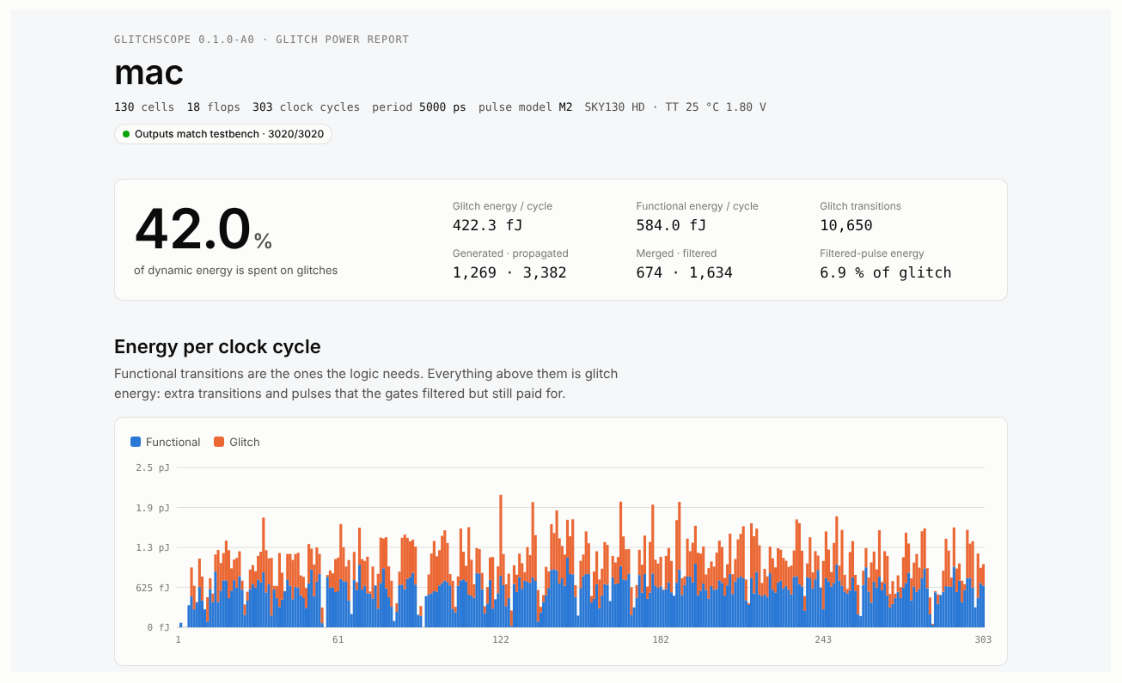

In [20]:
# [live] Run GlitchScope on the MAC now (~30 s). Needs only the open SKY130 Liberty file: if no PDK is installed, it is
# fetched (Apache-2.0, 12.8 MB) from OpenROAD-flow-scripts at the pinned commit used for every result in this notebook.
import urllib.request, hashlib
ORFS_LIB = ("https://raw.githubusercontent.com/The-OpenROAD-Project/OpenROAD-flow-scripts/"
            "ef421749a1050a8e9a197e7dfcd05396807f889d/flow/platforms/sky130hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib")
LIB = LIB or lib_path_or_none()
if LIB is None:
    LIB = ROOT / "sky130_fd_sc_hd__tt_025C_1v80.lib"
    try:
        if not LIB.exists():
            urllib.request.urlretrieve(ORFS_LIB, LIB)
        print("Liberty md5", hashlib.md5(LIB.read_bytes()).hexdigest(), "(expected 12a1d61fcd2982fc8ba63993919c8ff8)")
    except Exception as e:
        print("could not fetch the Liberty file, showing the cached run:", e); LIB = None


def glitchscope_cli(*args, timeout=3600):
    cmd = [sys.executable, "-c", "import sys; from glitchscope.flow import main; sys.exit(main())", *map(str, args)]
    r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True, timeout=timeout)
    if r.returncode:
        print(r.stdout[-1500:], r.stderr[-1500:])
    return r.returncode == 0


cached = (ROOT / "data/notebook/mac_flow/report.txt").read_text()
live = ROOT / "live/mac"
if LIB and glitchscope_cli("--netlist", "bench/netlists/mac.v", "--vcd", "bench/sim/mac.vcd", "--lib", LIB,
                           "--groups", "level:8", "--out", "live/mac"):
    report = (live / "report.txt").read_text()
    same = [l for l in report.splitlines() if "wrote" not in l and "open " not in l] == \
           [l for l in cached.splitlines() if "wrote" not in l and "open " not in l]
    print(report); print("LIVE RUN:", "identical to the cached report" if same else "differs from the cached report")
else:
    print(cached); print("(cached run)")
img = plt.imread(ROOT / "data/notebook/mac_flow/report.png")
fig = plt.figure(figsize=(10, 10 * img.shape[0] / img.shape[1])); ax = fig.add_axes([0, 0, 1, 1]); ax.imshow(img); ax.axis("off")

*Top of the interactive report (`data/notebook/mac_flow/report.html`; open it in a browser to hover, sort and filter).*
The outputs match the testbench on all 3,020 checks. Glitches are 42 % of the dynamic energy, triggered mostly by the
accumulator's middle bits, i.e. the carry chain of the adder that follows the multiplier.

**The automatic fix, live.** The next cell runs `--optimize` on the registered 8×8 array multiplier from section 6
(544 cells, 32 flip-flops). Every candidate placement is written out, verified on every cycle and measured. This
takes about 7 minutes on a desktop core and about 15 on Colab's free runtime; set `RUN_LIVE_OPTIMIZE = False` to show the cached run instead.

In [21]:
RUN_LIVE_OPTIMIZE = True
cache8 = json.loads((ROOT / "data/glitchfix/mul8_r/optimize.json").read_text())
live8 = ROOT / "live/mul8"
if RUN_LIVE_OPTIMIZE and LIB and glitchscope_cli(
        "--netlist", "bench/netlists/mul8_v0.v", "--random-vectors", 60, "--period-ps", 7000, "--lib", LIB,
        "--optimize", "--opt-cycles", 12, "--opt-final", 40, "--no-attribution", "--fixes", 0, "--out", "live/mul8"):
    print("\n".join(l for l in (live8 / "report.txt").read_text().splitlines() if "REDUCE" in l or "min-period" in l))
    print("LIVE RUN: wrote", (live8 / "optimized.v").relative_to(ROOT))
c = cache8
print(f"cached (scripts/glitchfix_study.py): total {c['original']['total']:.1f} -> {c['glitch_aware']['total']:.1f} fJ/cycle "
      f"({100 * (c['glitch_aware']['total'] / c['original']['total'] - 1):+.1f} %), "
      f"{c['original']['flops']} -> {c['glitch_aware']['flops']} flops; min-period retiming {c['timing_driven']['total']:.1f} fJ/cycle")

  REDUCE IT (register placement, verified on every cycle, latency +0): total 12103.7 -> 10715.7 fJ/cycle (-11.5 %), glitch 5972.8 -> 3403.2, 32 -> 43 flops; wrote live/mul8/optimized.v
    min-period retiming for comparison: 12355.5 fJ/cycle, 71 flops
LIVE RUN: wrote live/mul8/optimized.v
cached (scripts/glitchfix_study.py): total 12103.7 -> 10715.7 fJ/cycle (-11.5 %), 32 -> 43 flops; min-period retiming 12355.5 fJ/cycle


**A real core: the fast multiplier of PicoRV32.** The `pcpi_fast_mul` unit of the PicoRV32 RISC-V core (YosysHQ, ISC
licence; fetched at a pinned commit by `bench/picorv32/fetch.sh`, not redistributed) maps to 7,977 cells and 133
flip-flops. We drive it with a stream of back-to-back `MUL`/`MULH`/`MULHSU`/`MULHU` instructions with random operands
(`bench/picorv32/tb_fast_mul.v`, 50 MHz):

In [22]:
s = json.loads((ROOT / "data/picorv32/summary.json").read_text()); t = s["totals"]
Q = json.loads((ROOT / "data/picorv32/optimize.json").read_text()); o, g = Q["original"], Q["glitch_aware"]
print(f"{s['design']['cells']} cells, {s['design']['flops']} flip-flops, {s['design']['cycles']} cycles; outputs match the "
      f"testbench on {s['design']['output_check']['checked']:,} checks")
print(f"glitch energy: {100 * t['glitch_fraction']:.0f} % of the logic's dynamic energy, "
      f"{100 * o['glitch'] / o['total']:.0f} % of the total with flip-flops and clock")
print(f"--optimize: {o['total'] / 1e3:.1f} -> {g['total'] / 1e3:.1f} pJ/cycle ({100 * (g['total'] / o['total'] - 1):+.1f} %), "
      f"{o['flops']} -> {g['flops']} flip-flops, glitch energy {100 * (g['glitch'] / o['glitch'] - 1):+.0f} %")
print((ROOT / "data/picorv32/certificate.txt").read_text().strip())

7977 cells, 133 flip-flops, 304 cycles; outputs match the testbench on 10,605 checks
glitch energy: 53 % of the logic's dynamic energy, 36 % of the total with flip-flops and clock
--optimize: 49.9 -> 47.3 pJ/cycle (-5.4 %), 133 -> 100 flip-flops, glitch energy +3 %
CERTIFIED  legal retiming: 16477 connections, 7977 gates, lags -1..0, flip-flops 133 -> 100


Glitches are half of this multiplier's logic energy, but only about a third of its total energy once the 133
flip-flops and their clock are counted, so moving registers into the 33×33 array would cost more than it saves. The
tool's placement instead needs 33 fewer flip-flops (−5.4 %, a certified retiming). To check it, we also solved the
exact minimum-register program of section 7 on this design (`scripts/picorv32_exact_minreg.py`, under a minute): it
returns the same register placement (the retiming certificate between the two finds every lag equal) and the same
energy on every cycle. So on PicoRV32 the tool correctly falls back to classical register minimisation; there is no
glitch-aware gain to be had. For a design of this size the glitch-aware search is short, three placements in about
an hour of MILP time on 2 cores.

## 10. Conclusions, prior art and limitations

**Conclusions.** Pulse filtering decides glitch energy, and it depends on the cell and on the edges involved.
Calibrated in SPICE, it brings glitch counts from a 1.8–3× over-count to within 13 % on most circuits, and filtered
pulses still cost energy. Where to fix is something to measure rather than trace: on an array multiplier the two
answers point to opposite ends.

Measured and certified register placement turns this into a design change: −36 % in transistor-level SPICE of the
routed 16×16 multiplier at the same latency and clock, against −24 % for min-period retiming. On glitch-dominated
benchmarks it is 26–42 % below minimum-register retiming in the model; on c6288, checked in SPICE, it is 16 % below
minimum-register retiming and 21 % below GLOW, which keeps the minimum-register placement even when started from it.
It adds no registers where glitches do not pay. When the supply is chosen as well, it wins at every
throughput in the model.

Everything runs on open tools and an open PDK, and every cached result names the script that produced it (A11). Only
the GLOW comparison needs a Gurobi licence, and the SPICE confirmations took about 640 CPU-hours.

**Prior art.**

| Topic | Prior work | GlitchScope |
|---|---|---|
| Glitch power from delay-annotated simulation | commercial flows; GPU gate-level simulation (GATSPI, 2022) | open, on an open PDK, SPICE-validated |
| Per-cell SPICE filtering thresholds | Villegas & Vourkas, JLPEA 2024 (proprietary 32 nm) | open SKY130 data, filtered-pulse energy, closing-edge slope |
| Glitch-source ranking | structural trace-and-sum in commercial tools; SMART-GPO (ASP-DAC 2025, first-order sizing sensitivity) | interventional measurement with Shapley allocation |
| Glitch reduction by sizing / path balancing | Hashimoto et al., DAC 1999; Chen & Sarrafzadeh, DAC 1996; Benini et al., TVLSI 2000 | exact what-if measurement of local edits (A4) |
| Retiming for low power and glitches | Monteiro et al., ICCAD 1993; Schimpfle et al., ISCAS 1997; Hsieh et al., ASP-DAC 2008; GLOW, IWLS 2026 / ICCAD 2026 (to appear) | measurement-calibrated MILP, verified, confirmed after P&R and in SPICE, compared with GLOW |
| Open-source glitch power | multi-toggle detection + OpenSTA (Antmicro, 2026) | timing-aware, pulse-filtered, SAIF into OpenSTA (A3, A9) |

**Main limitations** (details in A10).
* M2 still over-counts glitches on deep reconvergent logic (1.36–1.41× in count; the 16×16 multiplier's logic energy
  1.48×), so absolute savings on arrays are optimistic (SPICE 36–37 % where the model predicts 47.5–49 %; c6288 16 % where
  it predicts 26 %). The
  rankings held in every SPICE check.
* The corner, mismatch and supply studies (section 8) are model simulations, not silicon; all SPICE runs are at the
  typical corner, with wires as lumped capacitances.
* Savings depend on the data, so `--optimize` should be run with representative stimulus (section 8).
* Only edge-triggered flip-flops are supported (no latches, clock gating or scan). Searches take 1.7 h (16×16
  multiplier) to 4.5 h (10 k cells) on 2 cores, and SAT proofs complete only for the smaller designs (every rewrite
  is certified structurally).
* The voltage-aware mode is a study script at the PDK's characterised supplies, not yet a command-line option.

---
# Appendix

| | |
|---|---|
| A1 | Closing-edge slope: the measurement behind M2's correction |
| A2 | Open-PDK reality check: Liberty vs SPICE, schematic vs extracted cells |
| A3 | Small benchmarks, and why counting toggles is not enough |
| A4 | How to fix locally: skew, buffering, resizing, pin swaps |
| A5 | The c6288-class multiplier in detail |
| A6 | An AI-accelerator processing element |
| A7 | Standard suites: glitch shares and run time |
| A8 | Six open technologies |
| A9 | MAC per-cycle validation, cycle sampling, compiled core, OpenSTA hand-off |
| A10 | Detailed limitations |
| A11 | Reproducing everything, tool versions, references |

## A1. Closing-edge slope

A second ngspice sweep (`scripts/trail_slew_sweep.py`: 12 cells, both pulse directions, two slews and two loads,
closing edges 0, 80 and 260 ps slower than the opening edge) measures the input width at which the output just
reaches VDD/2. The extra width needed grows linearly with the slope difference; its slope α belongs to the cell and
to the direction of the closing input edge (it acts early by roughly the part of its ramp before the transistor
turns on).

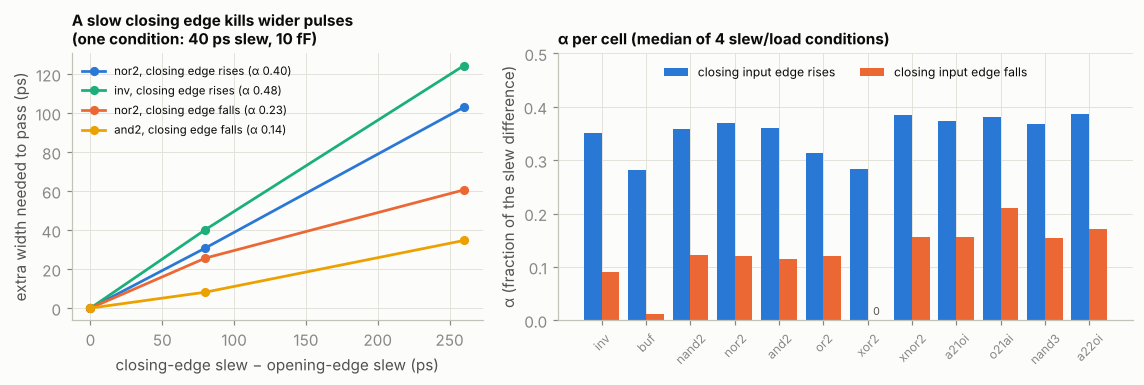

In [23]:
P.trail_slew();

The coefficients are measured on single cells, not fitted to circuits. On the 8×8 NOR array they reduce M2's
glitch over-count from 1.79× to 1.36×, on c432 from 1.51× to 1.41×.

## A2. Open-PDK reality check

**Liberty vs SPICE timing.** For the INV1 cell, the open SKY130 Liberty tables and open ngspice simulation of an
RC-extracted INV1 netlist differ by a median 16.5 % in delay (18 slew/load/polarity cases, correlation 0.987). A
factorial ablation of the extracted resistances shows why: the **supply-rail resistance** (VPWR for rising, VGND for
falling outputs) dominates. This is why M2 is normalised by each cell's SPICE delay.

Energy, Liberty (internal_power + CV^2) vs SPICE on extracted cells, 10 cells x 6 conditions: median 0.98x, range 0.68-1.45x


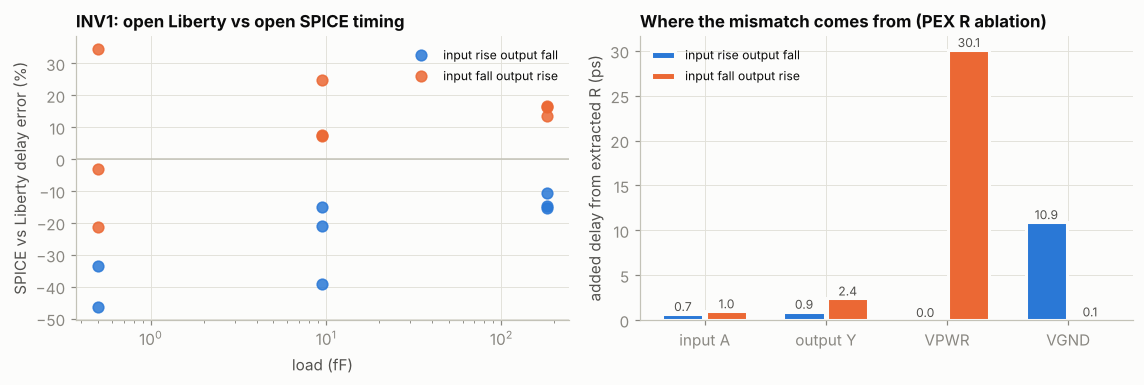

In [24]:
P.reality_check();
d = list(csv.DictReader(open(ROOT / "data/m2/liberty_vs_spice_energy.csv")))
r = np.array([float(x["ratio"]) for x in d])
print(f"Energy, Liberty (internal_power + CV^2) vs SPICE on extracted cells, {len(set(x['cell'] for x in d))} cells x 6 conditions: "
      f"median {np.median(r):.2f}x, range {r.min():.2f}-{r.max():.2f}x")

Liberty energy matches SPICE on extracted cells at a per-cell median of 0.98×, but not for every cell (XOR2 0.75×,
XNOR2 1.33×; the printed range is over individual conditions). GlitchScope therefore scales each cell's Liberty
energy by its measured ratio by default (`--no-spice-scale` reports plain Liberty energy).

**Schematic vs extracted cells.** The PDK's standard-cell SPICE netlists are schematics: no source/drain diffusion
areas and no wiring capacitance. We extracted the 13 cells used here (the 12 calibrated cells and `dfxtp`) from the
PDK's layouts with Magic (`scripts/extract_cells_pex.sh`) and repeated the single-cell sweeps on both; the 11 more cell
types that OpenROAD adds to the routed layouts (clock buffers, resized cells) were extracted the same way for
section 6 (24 in all).

In [25]:
px = json.loads((ROOT / "data/pdk/pex/pex_vs_schematic.json").read_text())
for k, lab in (("t_pd_ps", "delay"), ("E_full_fJ", "energy per full cycle"), ("r_filter", "normalised threshold r_filter")):
    v = np.array([r["ratio"][k] for r in px])
    print(f"extracted / schematic {lab:31s}: median {np.median(v):.2f}x  (range {v.min():.2f}-{v.max():.2f}x, {len(v)} conditions)")
cond = list(csv.DictReader(open(ROOT / "data/m2/m2_conditions.csv")))
e = np.array([float(r["E_full_pex_fJ"]) / float(r["E_full_fJ"]) for r in cond])
print(f"extracted / schematic energy, all {len(e)} M2 calibration conditions: median {np.median(e):.2f}x (range {e.min():.2f}-{e.max():.2f}x)")
ff = json.loads((ROOT / "data/pdk/pex/flop_energy.json").read_text())
print(f"dfxtp_1 flip-flop per idle clock cycle: schematic {ff['schematic']['idle_fJ']:.1f} fJ, extracted "
      f"{ff['pex']['idle_fJ']:.1f} fJ, Liberty clock-pin internal energy {ff['liberty_clock_internal_fJ']:.1f} fJ")

extracted / schematic delay                          : median 1.10x  (range 1.04-1.22x, 16 conditions)
extracted / schematic energy per full cycle          : median 1.16x  (range 1.08-1.31x, 16 conditions)
extracted / schematic normalised threshold r_filter  : median 0.99x  (range 0.90-1.16x, 16 conditions)
extracted / schematic energy, all 128 M2 calibration conditions: median 1.25x (range 1.08-1.46x)
dfxtp_1 flip-flop per idle clock cycle: schematic 17.9 fJ, extracted 33.8 fJ, Liberty clock-pin internal energy 40.0 fJ


The extracted cells are about 10 % slower and draw 16–25 % more energy per transition (up to 46 %), and a flip-flop's
idle clock energy nearly doubles, but the normalised rejection threshold stays put (median 0.99×, individual
conditions within ±16 %): M2's calibration holds for both. All transistor-level references in this notebook use the extracted cells; against the schematic netlists the
same GlitchScope energies would look 30–60 % high (hollow markers in section 3).

**Remaining over-count on deep logic** (`scripts/overcount_diagnosis.py`, `scripts/overcount_timing.py`): on the NOR
array the excess is created at NOR2 gates by glitches that two inputs generate about 140 ps apart and that stay below
VDD/2 in SPICE; it is spread over all logic depths. c432's glitches pass through complex gates whose delay depends on
the other inputs' state, while the PDK Liberty has one arc per pin. Re-characterising them with state-dependent arcs
(`scripts/charlib.py`) improves c432 to 1.27× but moves ks8 to 1.25× and the NOR array to 1.57×, so the PDK Liberty
stays the default. A separate sweep of two inputs switching in opposite directions (`scripts/generation_sweep.py`)
puts the thresholds of glitch *generation* within a median 7 % of M2's propagation thresholds.

## A3. Small benchmarks, and why counting toggles is not enough

Four small circuits mapped to basic SKY130 cells (8-bit ripple-carry and Kogge-Stone adders, 8-bit comparator, 4×4
array multiplier), checked against arithmetic on every vector:

bench   functional fJ/vec  glitch fJ/vec (M2)
rca8                188.8                36.1
ks8                 394.8                39.8
cmp8                156.6                 7.6
mul4                305.8               115.9


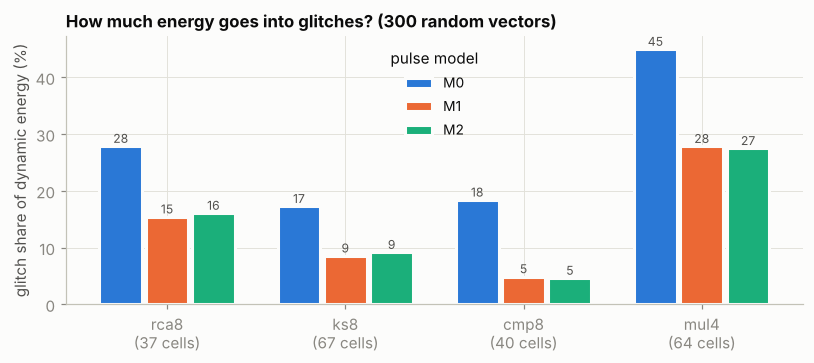

In [26]:
P.glitch_fraction();
b = json.loads((ROOT / "data/notebook/bench_energy.json").read_text())
print(f"{'bench':6s} {'functional fJ/vec':>18s} {'glitch fJ/vec (M2)':>19s}")
for k, v in b.items():
    print(f"{k:6s} {v['M2']['E_functional_fJ']/300:18.1f} {v['M2']['E_glitch_fJ']/300:19.1f}")

Pulse filtering cuts the estimate to 28–60 % of the unfiltered (M0) one. The prefix adder wastes a smaller share
than the ripple-carry adder but more energy in total.

A recent open-source flow (Antmicro, 2026) selects signals that toggle more than once per clock cycle and hands them
to OpenSTA. With zero-delay simulation there is nothing to count (no timing hazards at all); on a delay-annotated
trace, multi-toggle counting gets the number of glitch transitions within 0–9 %, but it cannot tell where to fix
(section 4):

In [27]:
n = json.loads((ROOT / "data/bench/naive_vs_causal.json").read_text())
print(f"{'bench':6s} {'zero-delay':>10s} {'multi-toggle':>13s} {'excess-only':>12s} {'functional mislabelled':>23s}")
for k, v in n.items():
    print(f"{k:6s} {v['zd_mt']:10d} {v['t_mt']:13d} {v['gs_m1_excess']:12d} {v['functional_mislabeled']:23d}")

bench  zero-delay  multi-toggle  excess-only  functional mislabelled
c17             0            32           32                       0
rca8            0          1112         1080                      32
ks8             0          1125         1112                      13
cmp8            0           304          304                       0
mul4            0          3031         2782                     249


## A4. How to fix locally: skew, buffering, resizing, pin swaps

Suppression potential is an upper bound. For every two-input hazard GlitchScope records the arrival skew and the
gate's rejection window (five of the strongest single fixes of the 4×4 multiplier, left), and measures path balancing by
buffer insertion (right):

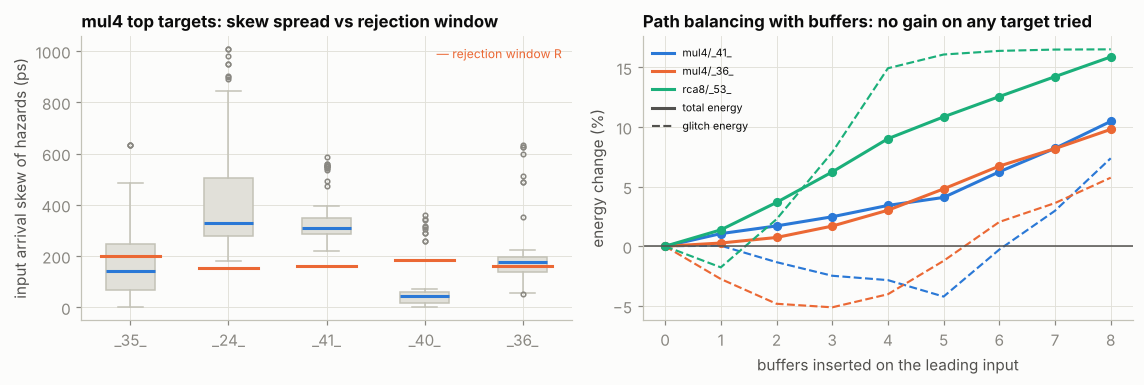

In [28]:
P.skew_and_balancing();

For most targets the skew is data-dependent (wide boxes), so no single delay cancels it; even where it is tight
(`_40_`, `_41_`: interquartile range about 50–60 ps), buffers remove at most about 5 % of glitch energy while their own switching raises total energy in every case.

**Function-preserving edits, measured by exact re-simulation:** resize a gate, swap logically symmetric pins (each pin
has its own timing arc and capacitance), or resize a driver. The targets are the six gates of the greedy joint fix set
(`scripts/counterfactual.py`, 300 vectors). The figure shows each gate's best edit for *glitch* energy; the table lists
the gates whose best edit for *total* energy lowers it.

cell   best edit                                         Δ total  Δ glitch  settle (ps)
_41_   driver _66_ (pin B): resize and2_1 -> and2_0       -0.14%    +0.15%  1813 -> 1813
_29_   driver _61_ (pin B): resize and2_1 -> and2_0       -0.25%    -0.30%  1813 -> 1813
_24_   driver _62_ (pin B): resize and2_1 -> and2_0       -0.22%    -0.15%  1813 -> 1813
_28_   driver _63_ (pin B): resize and2_1 -> and2_0       -0.13%    +0.17%  1813 -> 1813
all together: total -0.80 %, glitch -0.35 %, settle 1813 -> 1813 ps  (50 edits evaluated)


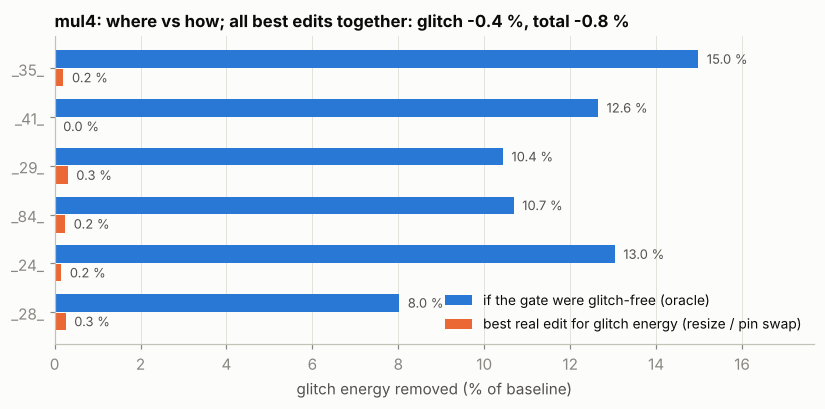

In [29]:
P.fix_gap(ROOT / "data/bench/whatif_mul4.json");
w = json.loads((ROOT / "data/bench/whatif_mul4.json").read_text())
print(f"{'cell':6s} {'best edit':48s} {'Δ total':>8s} {'Δ glitch':>9s}  settle (ps)")
for b in w["best"]:
    print(f"{b['cell']:6s} {b['edit']:48s} {b['dE_total_pct']:+7.2f}% {b['dE_glitch_pct']:+8.2f}%  "
          f"{b['settle_before_ps']:.0f} -> {b['settle_after_ps']:.0f}")
c = w["combined"]
print(f"all together: total {c['dE_total_pct']:+.2f} %, glitch {c['dE_glitch_pct']:+.2f} %, "
      f"settle {c['settle_before_ps']:.0f} -> {c['settle_after_ps']:.0f} ps  ({len(w['rows'])} edits evaluated)")

Upsizing never paid (0 of 38 upsizes); pin swaps (3 of 6) and downsizing (5 of 6, mostly drivers) did, but together
they save 0.8 % of total energy and 0.35 % of glitch energy, against 8–15 % at stake per gate. Glitch energy here is
set by path structure, which is why the automatic fix (section 6) moves registers instead.

## A5. The c6288-class multiplier in detail

`bench/gen_arraymul.py` builds the ISCAS c6288 architecture as an open SKY130 netlist: 2,368 cells (256 AND partial
products, 9-NOR full adders, a final ripple row), with hierarchical instance names (`r09c04_g3` = gate 3 of the adder in
row 9, column 4). A compiled C++ core and checkpoint/rollback for M2 decisions (both event-identical to the reference
engine) make this size practical.

In [30]:
st = json.loads((ROOT / "data/bench/arraymul16_study.json").read_text())
m = st["models"]
print(f"{m['cells']} cells, {m['vectors']} random vectors")
print(f"{'model':5s} {'glitch share':>12s} {'glitch transitions':>19s} {'functional':>11s} {'runtime':>8s}")
for k in ("M0", "M1", "M2"):
    print(f"{k:5s} {100*m[k]['totals']['glitch_fraction']:11.1f}% {m[k]['counts']['glitch_transitions']:19,d} "
          f"{m[k]['counts']['functional_transitions']:11,d} {m[k]['seconds']:7.0f}s")

2368 cells, 24 random vectors
model glitch share  glitch transitions  functional  runtime
M0           93.9%             388,820      21,904      22s
M1           88.7%             196,570      21,904      10s
M2           86.6%             146,654      21,904      25s


Glitches are 87 % of the logic's dynamic energy under M2, with almost seven glitch transitions per functional one;
transport delay (M0) counts 2.7× as many glitch transitions. On the four best single gates the best local edit saves
at most 0.1 % of total energy, 0.2 % together. The full interactive report of this design comes from one command:

```bash
glitchscope --netlist bench/netlists/arraymul16.v --random-vectors 24 --seed 7 --lib $GS_LIB \
            --groups 'regex:^(pp|r\d\d|rf)' --max-screen 12 --fixes 2 --perms 4 --out arraymul16_report
```

The layouts of section 5 are routed, extracted and DRC-clean in Magic; there is no LVS (A10).

## A6. An AI-accelerator processing element

A 4-lane signed int8 dot product with registered inputs and output (`bench/rtl/dot4_i8.v`, the core of a
systolic-array or vector-unit PE, 133 MHz), synthesised by Yosys/ABC with the default multiplier mapping and with
radix-4 Booth recoding plus a Wallace tree:

In [31]:
print(f"{'PE architecture':18s}{'cells':>7s}{'logic, functional':>19s}{'logic, glitch':>15s}{'flip-flops':>12s}{'total':>8s}   (pJ per cycle)")
for a, lab in (("plain", "array (default)"), ("booth", "Booth + Wallace")):
    Q = json.loads((ROOT / f"data/glitchfix/dot4_{a}/optimize.json").read_text())
    o = Q["original"]
    txt = (ROOT / f"bench/netlists/dot4_{a}.v").read_text()
    ncell = txt.count("sky130_fd_sc_hd__") - txt.count("sky130_fd_sc_hd__dfxtp")
    print(f"{lab:18s}{ncell:7d}{o['functional'] / 1e3:19.1f}{o['glitch'] / 1e3:15.1f}"
          f"{(o['flop_clock'] + o['flop_data']) / 1e3:12.1f}{o['total'] / 1e3:8.1f}")
    for k, l2 in (("min_register", "min-register retiming"), ("timing_driven", "min-period retiming"),
                  ("glitch_aware", "GlitchScope")):
        r = Q[k]
        print(f"    {l2:24s}{r['total'] / 1e3:6.1f} pJ ({100 * (r['total'] / o['total'] - 1):+5.1f} %), "
              f"glitch {r['glitch'] / 1e3:5.1f} pJ, {r['flops']} flip-flops")

PE architecture     cells  logic, functional  logic, glitch  flip-flops   total   (pJ per cycle)
array (default)      2058               12.2           13.9        10.0    36.2
    min-register retiming     30.7 pJ (-15.2 %), glitch  13.6 pJ, 36 flip-flops
    min-period retiming       39.0 pJ ( +7.8 %), glitch   7.0 pJ, 177 flip-flops
    GlitchScope               30.7 pJ (-15.2 %), glitch  13.6 pJ, 36 flip-flops
Booth + Wallace      1485                9.4           16.4        10.1    36.0
    min-register retiming     30.8 pJ (-14.6 %), glitch  16.0 pJ, 36 flip-flops
    min-period retiming       37.3 pJ ( +3.5 %), glitch   8.8 pJ, 164 flip-flops
    GlitchScope               30.8 pJ (-14.6 %), glitch  16.0 pJ, 36 flip-flops


* **Booth recoding trades logic for glitches.** It needs 28 % fewer cells and 23 % less functional switching, but
  its deeper, more reconvergent tree raises glitch energy by 18 %, so both PEs burn about 36 pJ per cycle before
  layout; glitches rise from 53 % to 64 % of logic energy. A cell-count or zero-delay estimate would credit Booth with
  a saving that is not there.
* **Registers first.** Flip-flops and their clock take more than a quarter of the energy, and the biggest win is
  needing fewer of them: minimum-register retiming moves the 82 boundary flip-flops to 36 positions (−15 %).
  GlitchScope's glitch-aware candidates (48–61 flip-flops) are 1–3 points better before layout, within the 5 % tie,
  so the tool returns minimum-register retiming. Min-period retiming makes both PEs worse (+8 % and +4 %).

In [32]:
PE = json.loads((ROOT / "data/layout/pe_summary.json").read_text())
print(f"{'PE':22s}{'flip-flops':>11s}{'glitch pJ':>11s}{'power mW':>10s}{'area um2':>10s}{'slack ns':>10s}")
for k, r in PE.items():
    o = PE[k.replace("_ga", "_v0")]
    d = f"({100 * (r['opensta_mW']['Total'] / o['opensta_mW']['Total'] - 1):+.0f} %)" if k.endswith("_ga") else ""
    print(f"{('array' if r['arch'] == 'plain' else 'Booth') + ', ' + r['placement']:22s}{r['flops']:11d}{r['E_glitch_pJ']:11.1f}"
          f"{r['opensta_mW']['Total']:10.2f}{r['area_um2']:10.0f}{r['opensta_mW']['slack_ns']:10.2f}  {d}")

PE                     flip-flops  glitch pJ  power mW  area um2  slack ns
array, original                82       13.6      5.31     15017      0.39  
array, GlitchScope             36       13.6      4.78     14194      0.45  (-10 %)
Booth, original                82       19.3      5.55     11584      0.55  
Booth, GlitchScope             36       15.3      4.45     10623      0.67  (-20 %)


* **After layout (OpenROAD, 133 MHz, power from OpenSTA with GlitchScope's activity): −10 % power on the array PE
  and −20 % on the Booth PE**, with 5.5 % and 8.3 % less cell area and more timing slack.
* **Why the tie rule:** with an earlier version of the rule, which compared only GlitchScope's own candidates, the 48- and 52-flip-flop glitch-aware placements measured −15 %
  on both PEs after layout. The two choices differ by about 5 points, in opposite directions on the two PEs.
  Differences of this size are not predicted reliably before layout, so the tool takes the cheaper design.
* **The Booth trap:** before the fix the Booth PE has 23 % less cell area but burns 5 % more power than the array
  PE, because its glitch energy is 42 % higher once real wires are in. With 36 flip-flops each, the Booth PE becomes
  the lower-power design (4.45 vs 4.78 mW).

## A7. Standard suites: glitch shares and run time

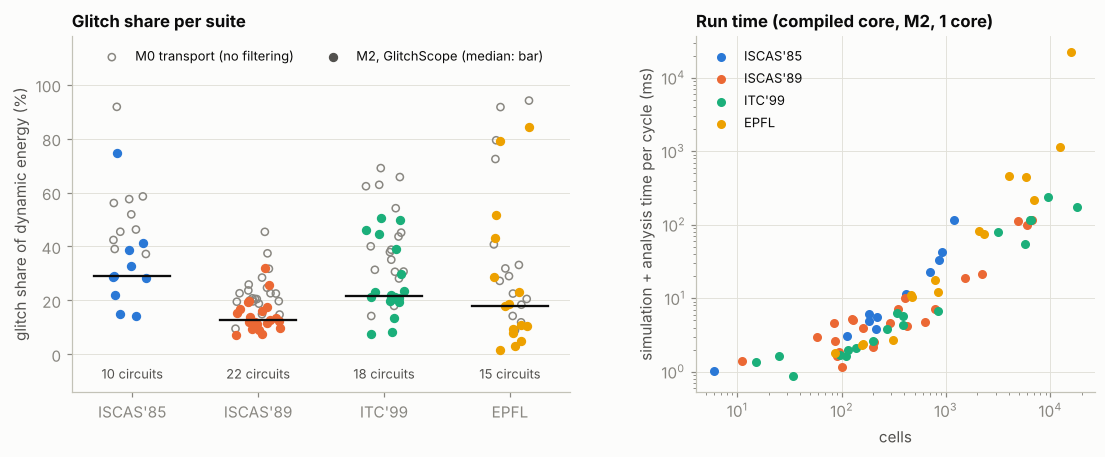

In [33]:
P.benchmark_suite();

Run time (compiled core, M2, one core) is at most 0.5 s per clock cycle for all but two circuits (0.18 s for the
largest, ITC'99 b17 with 17,860 cells), and it grows with glitch activity rather than size: the EPFL 64×64 multiplier
(15,824 cells, 84 % glitch share) needs 22 s per cycle, spent mostly resolving filtered pulses that had already fired.

## A8. Six open technologies

GlitchScope is library-independent: cells, flip-flops, units, supply and pulse calibration come from the Liberty file
(and, for M2, from a SPICE calibration of that library). The same 16×16 array multiplier was built from each library's
own unit-drive INV / NOR2 / AND2 cells and driven at its own fan-out-of-4 edge rate:

| PDK | node | supply | pulse calibration |
|---|---|---|---|
| GF180MCU (7-track) | 180 nm | 3.3 V | SPICE (ngspice, BSIM4), 2,592 runs |
| SKY130 HD | 130 nm | 1.8 V | SPICE (section 2) |
| IHP SG13G2 | 130 nm | 1.2 V | Liberty only (PSP models need OpenVAF) |
| Nangate45 / FreePDK45 | 45 nm | 1.1 V | Liberty only |
| ASAP7 (predictive) | 7 nm | 0.7 V | Liberty only |
| GT2N (predictive nanosheet) | 2 nm | 0.7 V | Liberty only |

PDK           FO4 slew  E/mult (M1)    glitch share M0/M1/M2   M0/M1 glitches
GF180MCU       422.7ps     589.25pJ           94.6/89.7/87.8          2.00×
SKY130 HD       68.0ps      94.63pJ           93.9/88.7/86.6          1.97×
IHP SG13G2      53.4ps      60.63pJ              94.9/89.6/–          2.20×
Nangate45       13.8ps      28.70pJ              93.2/89.2/–          1.62×
ASAP7           32.9ps       1.82pJ              95.8/89.2/–          2.69×
GT2N             6.1ps       1.87pJ              95.5/89.0/–          2.55×

median r_filter (pulse filtered below r x gate delay):
pdk               GF180  SKY130
cell    polarity               
and2_1  negative   1.09    1.12
        positive   0.76    0.75
inv_1   negative   1.10    1.18
        positive   1.45    1.40
nand2_1 negative   1.13    1.17
        positive   1.43    1.39
nor2_1  negative   1.11    1.28
        positive   1.36    1.17
xor2_1  negative   1.08    1.01
        positive   1.35    0.66


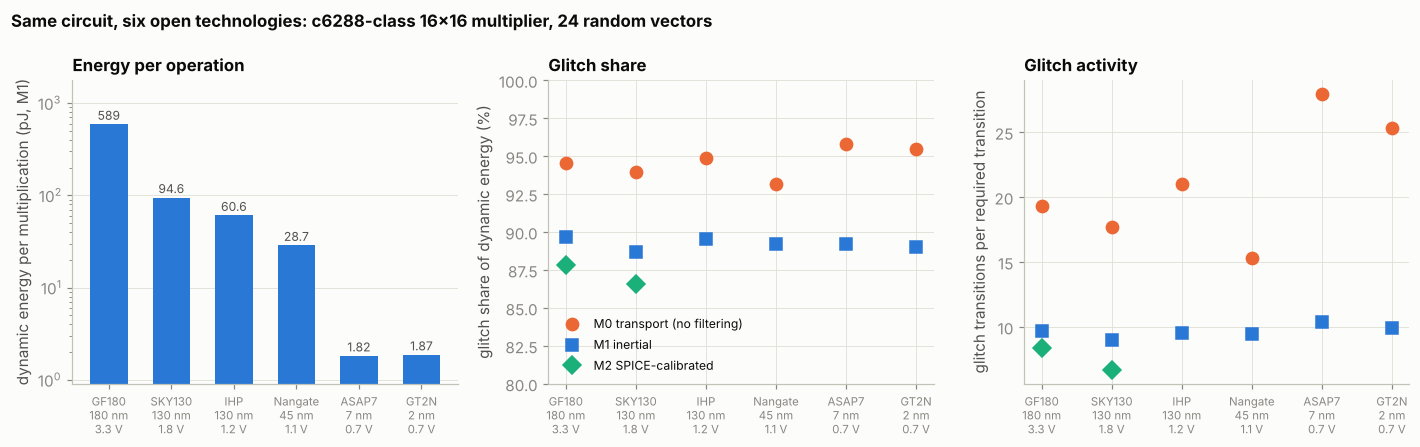

In [34]:
P.pdk_trend();
T = json.loads((ROOT / "data/pdk/trend.json").read_text())
print(f"{'PDK':12s} {'FO4 slew':>9s} {'E/mult (M1)':>12s} {'glitch share M0/M1/M2':>24s} {'M0/M1 glitches':>16s}")
for r in sorted(T.values(), key=lambda r: -r["node_nm"]):
    M = r["models"]
    sh = "/".join(f"{100*M[m]['totals']['glitch_fraction']:.1f}" if m in M else "–" for m in ("M0", "M1", "M2"))
    oc = M["M0"]["counts"]["glitch_transitions"] / M["M1"]["counts"]["glitch_transitions"]
    print(f"{r['label']:12s} {r['input_slew_ps']:7.1f}ps {M['M1']['totals']['E_total_fJ']/r['vectors']/1e3:10.2f}pJ "
          f"{sh:>24s} {oc:13.2f}×")
import pandas as pd
sk = pd.read_csv(ROOT / "data/m2/m2_conditions.csv"); gf = pd.read_csv(ROOT / "data/pdk/gf180mcu_7t_3v3/m2_conditions.csv")
cmp = pd.concat([sk.assign(pdk="SKY130"), gf.assign(pdk="GF180")])
cmp = cmp[cmp.cell.isin(["inv_1", "nand2_1", "nor2_1", "xor2_1", "and2_1"])]
print("\nmedian r_filter (pulse filtered below r x gate delay):")
print(cmp.groupby(["cell", "polarity", "pdk"]).r_filter.median().unstack().round(2).to_string())

* Energy per multiplication falls about 320× from GF180 to ASAP7 / GT2N (GT2N comes out slightly above ASAP7; both are
  predictive libraries, and we did not investigate the small difference).
* In this multiplier the glitch share is 87–90 % of dynamic energy at every node (M2 where calibrated, M1 at the four
  other nodes): its unequal path depths create the same relative waste everywhere.
* Without filtering (M0), 1.6–2.2× as many glitch transitions are counted as with inertial filtering (M1) at 45–180 nm, and 2.6–2.7× in the
  predictive 7 nm and 2 nm libraries, where gate delays are short relative to input edges.
* Measured relative to its own delay, an inverter or NAND2 filters pulses at nearly the same ratio in GF180 and
  SKY130; XOR2 does not (1.35× vs 0.66×), so each library needs its own calibration (`scripts/calibrate_pdk.py`).
  Proprietary nodes work the same way on your own machine (`docs/USING_YOUR_OWN_PDK.md`); no foundry data is used here.

## A9. MAC per-cycle validation, cycle sampling, compiled core, OpenSTA hand-off

**Per-cycle energy of the MAC vs SPICE** (real flip-flops on their own supply) is checked by
`scripts/validate_design_vs_spice.py`; its summary is the MAC row of section 3's figure.

**Long testbenches: cycle sampling.** Each cycle's start state is known from the functional model, so cycles can be
simulated independently. `--sample N` simulates a stratified random sample and reports the glitch energy with a 95 %
confidence interval. On the MAC, 60 of 303 cycles give 412 fJ/cycle [361, 463] against 422 for the full run, and the
same top-3 gates (`scripts/sampling_study.py`, 20 random samples per size).

Samples of 20–40 cycles under-cover (per-cycle energy is skewed); from about 80 cycles 19 of 20 random samples covered the
full-run value, with ±10 % intervals. With 20 trials per size these coverage figures are themselves uncertain by
about ±10 points.

**Compiled core.** The event simulator also exists as a C++ kernel (compiled with the system `g++` on first use; pure
Python fallback), checked event by event against the Python engine on all benchmarks and models
(`scripts/check_native_equivalence.py`: 0 mismatches):

In [35]:
sp = json.loads((ROOT / "data/bench/native_speed.json").read_text())["rows"]
print(f"{'design':11s}{'cells':>6s}{'M1 kernel':>11s}{'M2 kernel':>11s}{'M2 run()':>10s}{'analyze':>9s}   (speed-up vs Python)")
for r in sp:
    print(f"{r['bench']:11s}{r['cells']:6d}{r['M1_kernel_speedup']:10.0f}x{r['M2_kernel_speedup']:10.0f}x"
          f"{r['M2_speedup']:9.1f}x{r['analyze_speedup']:8.1f}x")

design      cells  M1 kernel  M2 kernel  M2 run()  analyze   (speed-up vs Python)
mul4           64        20x         6x      2.4x     2.3x
mac           130        24x        23x      5.7x     2.3x
arraymul16   2368        58x        34x     29.7x    18.9x


**Hand-off to OpenSTA.** GlitchScope's SAIF annotates OpenSTA's power analysis. OpenSTA's default activity is a
probabilistic estimate propagated from a default input toggle rate, not the testbench's activity; with GlitchScope's
SAIF, OpenSTA's combinational power (215 µW) matches GlitchScope's estimate with plain Liberty energy (208 µW, of which
88.5 µW glitch; the SPICE-scaled default of section 9 gives 201 µW).

In [36]:
log = (ROOT / "data/bench/opensta_saif_check_mac.log").read_text().splitlines()
print("\n".join(l for l in log if l.startswith(("=====", "Annotated", "Combinational", "GlitchScope"))))

===== 1) OpenSTA default (propagated, glitch-free) activity =====
Combinational          8.28e-05   9.16e-05   2.66e-10   1.74e-04  48.1%
===== 2) GlitchScope glitch-accurate activity (SAIF) =====
Annotated 466 pin activities.
Combinational          1.00e-04   1.15e-04   2.74e-10   2.15e-04  51.5%
GlitchScope reference (Liberty energy, same activity): combinational dynamic = 207.9 uW, of which glitch = 88.5 uW


## A10. Detailed limitations

* **`--optimize`.** The calibrated MILP is exact only for its own linear model; measurement decides among its solutions
  and the arrival-time cuts, and neither is guaranteed to find the lowest-energy placement. On the largest ITC'99
  circuits (6–10 k cells) the open solver finds no solution of the full program in time, and the neighbourhood search
  found at most 0.6 % below minimum-register retiming (b21). Timing during the search is GlitchScope's own static timing
  with a 15 % wire margin; the post-layout check is OpenROAD's. Registers moved inside a loop power up in a different
  state, so the design must be initialised by its own clear (as the original). Retiming may move boundary registers
  into the logic (`--keep-io-registers` prevents it). Clock-tree energy per flip-flop is calibrated on this study's
  OpenROAD clock trees.
* **Glitch model.** M2 is calibrated at the typical corner (12 cells) and at the slowest corner (8 cell functions);
  other corners reuse the typical calibration, and the closing-edge coefficients exist for SKY130 HD only. Liberty and
  SPICE differ by about 16 % in delay, so absolute glitch widths inherit that uncertainty. Uncalibrated cell functions
  fall back to M1. Before the closing-edge effect was found, four other corrections were tested against the SPICE
  references and rejected (pulse narrowing, separate generation thresholds, SPICE-characterised delays, uniformly
  higher thresholds).
* **Scope.** Combinational logic between edge-triggered flip-flops; async set/reset is applied at the clock edge. Local
  mismatch is a per-instance delay factor (no slew or energy variation); global and local variation are studied
  separately.
* **Attribution** re-simulates: seconds to minutes on hundreds of cells, about 16 minutes for the 2,368-cell
  multiplier's two group studies on 2 cores; single-cell screening on such designs is capped. A glitch-free gate is an
  ideal intervention: it bounds, but does not implement, a fix.
* **Layout.** Post-layout analysis uses each net's lumped extracted capacitance (no RC delay along wires) and one clock
  arrival time for all flip-flops. OpenROAD's detailed router reports 0 DRC and 0 antenna violations in the
  five route logs included here (the other five logs were overwritten by a later no-op re-run). Independently, each routed DEF was streamed to GDS with KLayout and ORFS's
  `def2stream.py`, as `make gds` does, and checked by Magic with the PDK's own setup (`sky130A.magicrc`, `drc(full)`,
  Euclidean spacing): 0 violations on all ten layouts (`scripts/klayout_drc.sh`, `scripts/magic_drc_gds.sh`).
  An earlier route, where Magic itself imported the DEF, gave 3,713 flags on V2, all at via and pin-access geometry;
  the same Magic check on that GDS still reproduces them, so they come from Magic's DEF import, not from the layout.
  KLayout's own rule deck could not be run (the conda-forge KLayout build has no Ruby), and no LVS was run.

## A11. Reproducing everything

Runtimes on 2 cores of a cloud workspace unless stated.

| Result | Script | Runtime |
|---|---|---|
| Unit and regression tests (76) | `python scripts/run_tests.py` | ~2 min |
| M2 pulse calibration (12 cells) | `scripts/run_m2_sweep.py`, `scripts/calibrate_cells.py`, `scripts/fit_m2.py` | ~15 min |
| Closing-edge calibration | `scripts/trail_slew_sweep.py <lib>`, `scripts/trail_slew_eval.py <lib> 0 model --pex` | ~2 h, ~5 min |
| Extracted cells and their effect | `scripts/extract_cells_pex.sh`, `scripts/pex_vs_schematic.py`, `scripts/pex_energy_reference.py`, `scripts/flop_energy.py` | ~1 min, ~1 h, ~10 min, ~1 min |
| Liberty vs SPICE energy | `scripts/compare_liberty_energy.py <lib> --pex` | seconds |
| Whole-circuit SPICE validation (section 3) | `GS_CELL_SPICE=data/pdk/pex/sky130_fd_sc_hd_pex.spice scripts/validate_vs_spice.py …`, `scripts/validate_design_vs_spice.py …` | 5 min–6 h each |
| Over-count diagnosis, state-dependent arcs | `scripts/overcount_diagnosis.py`, `scripts/overcount_timing.py`, `scripts/charlib.py` | ~5 min, ~1 h, minutes per cell |
| Attribution studies (section 4, A3, A4) | `scripts/counterfactual.py`, `scripts/attribution_shift.py`, `scripts/naive_compare.py`, `scripts/fix_study.py <lib> mul4`, `scripts/skew_study.py <lib> mul4 rca8` | 1–2 min each |
| c6288-class multiplier (section 4, A5) | `python bench/gen_arraymul.py 16`, `scripts/arraymul_study.py <lib> 24` | ~1 h |
| Layout study (section 5) | `scripts/layout_flow.sh v0|v1|v2`, `scripts/layout_summary.py --pre`, `scripts/klayout_drc.sh` (GDS via KLayout), `scripts/magic_drc_gds.sh <gds> <top> <log>` | ~10 min per layout, DRC < 1 min |
| Automatic placement (section 6, A6) | `scripts/glitchfix_study.py <lib>`, `scripts/layout_flow.sh r_ga|r_td|r_milp`, `scripts/pe_layout_summary.py`, `scripts/iverilog_equivalence.py …` | ~6 h + ~10 min per layout |
| Post-layout transistor-level SPICE (section 6) | `scripts/spice_confirm_postlayout.py run <lib>`, then `… merge <lib>` (routed netlists and wire capacitances in `data/layout/*/`); on a server `scripts/server_spice_kit.sh postlayout` | 193 CPU-h (128-core server: ~8 h for all three in parallel) |
| Transistor-level confirmation (section 6) | `scripts/spice_confirm_parallel.py run <lib> mul16_r --cells pex --cycles 40` (and `mul8_r --cycles 48`), then `… merge …`; on a server `scripts/server_spice_kit.sh` | 16×16: 284 CPU-h; 8×8: 29 CPU-h (128-core server: ~4 h per design, designs in parallel) |
| Equivalence of rewritten netlists (section 6) | `scripts/retiming_certificate.py <lib> <original.v> <new.v> [latency]` (structural proof), `scripts/formal_equivalence.py …` (SAT, Yosys + ABC) | seconds; minutes to timeout |
| Voltage-aware placement (section 8) | `scripts/vdd_aware_study.py search <lib> 5500` (and `4800`), `… corners <PDK lib dir>`, `… select` | ~1 h each search, ~40 min, seconds |
| PicoRV32 fast multiplier (section 9) | `bench/picorv32/fetch.sh`, `bench/synth_seq.sh … picorv32_pcpi_fast_mul` (move the netlist to `bench/external/netlists/`), Icarus on `bench/picorv32/tb_fast_mul.v`, then `glitchscope --netlist … --vcd … --optimize --opt-cycles 12 --opt-final 60`; `scripts/picorv32_exact_minreg.py <lib> <optimized.v>` | ~1 min, ~1 h, ~5 min |
| Die-level glitch map (front page) | `scripts/layout_glitch_map.py <lib>` | ~1 min |
| Standard suites (section 7, A7) | `bench/fetch_benchmarks.py`, `scripts/benchmark_suite.py <lib> --cycles 30 --max-cells 20000` | ~1 h + ~1 h |
| Register placement on benchmarks (section 7) | `scripts/retiming_benchmarks.py <lib> [--factor 0] …` | ~9 h (ITC'99) + ~10 h (arithmetic, both clocks) |
| GLOW head-to-head (section 7) | `scripts/glow_compare.py export/import <lib> <case>`, GLOW with Gurobi (`scripts/glow_run_all.sh`); warm starts: `scripts/glow_warmstart.py lags/patch`, `scripts/server_spice_kit.sh glow7` | 1 h per GLOW run |
| c6288 in SPICE (section 7) | `GS_SAVE_NETLISTS=bench/external/retime_netlists scripts/retiming_benchmarks.py <lib> c6288_r --factor 0` and `… glow_compare.py import …`, then `scripts/spice_confirm_parallel.py run/merge <lib> c6288_r --tags original,min_register,glitchscope,glow_sim` | 136 CPU-h (4 h on 40 cores) |
| Corners, mismatch, supply scaling (section 8) | `scripts/pvt_study.py <PDK lib dir>` (and `--compare-calibration ss_n40C_1v28`), `scripts/mismatch_sigma.py 80`, `scripts/mismatch_study.py <lib> 30`, `scripts/calibrate_corner.py ss_n40C_1v28`, `scripts/iso_throughput.py` | ~20 min, ~25 min, ~35 min, ~1 h, seconds |
| Operand workloads (section 8) | `scripts/workload_study.py <lib> 40`, `scripts/workload_optimize.py <lib> dnn_int8` | ~5 min, ~22 min |
| Six technologies (A8) | `scripts/prep_libs.py <ORFS> <dir>`, `scripts/calibrate_pdk.py gf180mcu_7t_3v3`, `scripts/pdk_study.py <dir> 24 16` | ~15 min |
| MAC report and screenshot (section 9) | `glitchscope --netlist bench/netlists/mac.v --vcd bench/sim/mac.vcd --lib <lib> --groups level:8 --out data/notebook/mac_flow`, `scripts/report_screenshot.py` | ~1 min |
| Sampling, compiled core, OpenSTA (A9) | `scripts/sampling_study.py`, `scripts/check_native_equivalence.py`, `scripts/native_speed.py`, `scripts/opensta_saif_check.sh` | minutes |
| Every model-dependent result after a model change | `scripts/rerun_all.sh` (two lanes; SPICE references and GLOW runs reused) | ~10 h |
| This notebook | `python scripts/build_notebook.py` | ~1 min |

**Tool versions (tested).** Python 3.13 · numpy 2.5 · pandas 3.0 · matplotlib 3.11 · Yosys 0.65 · Icarus Verilog 14
(devel) · ngspice-47 (a server with ngspice-42 reproduced the transistor-level runs within 0.01 %) · OpenSTA d1e43c6 ·
OpenROAD 0907a86 + OpenROAD-flow-scripts ef42174 · Magic 8.3.685 · SKY130A via Ciel `0fe599b` · ORFS
`sky130_fd_sc_hd__tt_025C_1v80.lib`. Paths are set in `tools.env`. The optional Colab install in the setup cell pins
the last litex-hub builds (micromamba 1.5.10; Yosys 0.38, OpenROAD 2.0-12381, ngspice 39.3, open_pdks 1.0.471), older
than the tools above: enough for live runs of the analyser, while the cached results come from the versions listed.

**Reused work.** No notebooks were reused. External code run, not redistributed: GLOW (open source, Apache-2.0) for
the comparison in section 7, PicoRV32 (ISC licence) in section 9; benchmark sources are fetched at pinned commits by
`bench/fetch_benchmarks.py` and `bench/picorv32/fetch.sh`. MILPs are solved by HiGHS through SciPy 1.18.

**References.** C. E. Leiserson, J. B. Saxe, "Retiming synchronous circuitry," *Algorithmica* 6, 1991 · J. Monteiro,
S. Devadas, A. Ghosh, "Retiming sequential circuits for low power," ICCAD 1993 · C. V. Schimpfle, S. Simon,
J. A. Nossek, "Optimal placement of registers in data paths for low power design," ISCAS 1997 · C.-T. Hsieh, J. Cong,
Z. Zhang, S.-C. Chang, "Behavioral synthesis with activating unused flip-flops for reducing glitch power in FPGA,"
ASP-DAC 2008 · J. Liu et al., "GLOW: glitch optimization with retiming for low power," IWLS 2026; ICCAD 2026 (to
appear) · B. Villegas, I. Vourkas, *J. Low Power Electron. Appl.* 14(3):41, 2024 · Y. Ouyang et al., "SMART-GPO,"
ASP-DAC 2025 · M. Hashimoto, H. Onodera, K. Tamaru, "A practical gate resizing technique considering glitch
reduction for low power design," DAC 1999 · D.-S. Chen, M. Sarrafzadeh, "An exact algorithm for low power
library-specific gate re-sizing," DAC 1996 · L. Benini et al., "Glitch power minimization by selective gate
freezing," IEEE TVLSI 8(3), 2000 · F. Brglez, H. Fujiwara, ISCAS-85 benchmarks, 1985 · F. Corno, M. Sonza Reorda,
G. Squillero, ITC'99 benchmarks, 2000 · L. Amarú, P.-E. Gaillardon, G. De Micheli, EPFL combinational benchmark
suite, IWLS 2015 · N. Chabini, W. Wolf, "Reducing dynamic power consumption in synchronous sequential digital
designs using retiming and supply voltage scaling," IEEE TVLSI 12(6), 2004 · L. S. Shapley, "A value for n-person
games," 1953 · T. Ajayi et al., "OpenROAD: toward a self-driving, open-source digital layout implementation tool
chain," GOMACTech 2019 · Q. Huangfu, J. A. J. Hall, "Parallelizing the dual revised simplex method," Math. Prog. Comp.
10, 2018 (HiGHS) · C. Wolf, PicoRV32 (YosysHQ) · Y. Zhang et al., "GATSPI," DAC 2022 · Antmicro, glitch/peak power estimation with OpenROAD, 2026 ·
SkyWater SKY130 PDK; OpenROAD / OpenSTA; Yosys; Icarus Verilog; ngspice; Magic; HiGHS.